# Лабораторна робота 5. Частина 1. Власний проєкт донавчання

**Задача:** перетворити пошуковий запит користувача інтернет-магазину електроніки (українською, інколи російською чи англійською) на **структурований JSON-фільтр** для пошуку по каталогу.

| | |
|---|---|
| Модель | `Qwen/Qwen3-1.7B` (Apache 2.0) |
| Метод | SFT з LoRA (`trl` + `peft`), fp16 |
| Залізо | безкоштовний Colab, GPU **T4** (15 GB) |
| Дані | власний генератор синтетичних запитів + 70 запитів, складених і розмічених вручну (не з логів реального магазину) |
| Орієнтовний час | ≈ 35–40 хв (у виміряному запуску клітинки виконувались сумарно 32 хв): порівняння промптів ≈ 12 хв, тренування ≈ 10 хв, оцінка після й вимірювання затримки ≈ 7 хв |

**Як запускати.** `Runtime → Change runtime type → T4 GPU`, потім `Runtime → Run all` (або виконуйте клітинки зверху вниз; **першою** — службову клітинку з таймером). Якщо сесія перезапустилась, починайте з початку: ноутбук відтворює всі дані з фіксованого seed. Ваги адаптера зберігаються в папці `ft_adapter` лише в сесії Colab; **у репозиторій їх додавати не потрібно**.

Структура відповідає вимогам завдання: **1.1** задача → **1.2** модель і дані → **1.3** метрика й оцінка до донавчання → **1.4** донавчання → **1.5** порівняння, аналіз помилок і перевірка загальних здібностей → **1.6** звіт.

In [1]:
# Службова клітинка до питання про тривалість: запамʼятовує, скільки секунд виконувалася кожна клітинка.
# Запускайте її першою, до всіх інших клітинок ноутбука.
import json
import os
import time

from IPython import get_ipython

TIMES_FILE = "cell_times_ft.json"  # файл переживе перезапуск середовища в межах сесії Colab
CELL_TIMES = json.load(open(TIMES_FILE)) if os.path.exists(TIMES_FILE) else []
_started = [None]


def _pre_run(*args):
    _started[0] = time.perf_counter()


def _post_run(result=None):
    if _started[0] is None:  # саму службову клітинку не вимірюємо
        return
    raw = (getattr(getattr(result, "info", None), "raw_cell", "") or "").strip()
    CELL_TIMES.append({
        "cell": getattr(result, "execution_count", None),
        "sec": round(time.perf_counter() - _started[0], 1),
        "code": raw.splitlines()[0][:70] if raw else "",
    })
    with open(TIMES_FILE, "w") as f:
        json.dump(CELL_TIMES, f)


ip = get_ipython()
for event, callback in (("pre_run_cell", _pre_run), ("post_run_cell", _post_run)):
    for old in list(ip.events.callbacks[event]):
        if getattr(old, "__name__", "") == callback.__name__:
            ip.events.unregister(event, old)
    ip.events.register(event, callback)
print("Таймер клітинок увімкнено")

Таймер клітинок увімкнено


## 1.1. Задача

**Хто користувач.** Покупець в інтернет-магазині електроніки або розробник пошукової системи товарів, яка має зрозуміти запит природною мовою: «айфон 13 128гб синій до 25 тис», «наушники беспроводные дешевле 1500», «монітор 27 дюймів 144 гц».

**Вхід і вихід.** Вхід — рядок запиту. Вихід — один JSON-обʼєкт із фіксованими полями, який без обробки передається в код пошуку (фільтри по каталогу):

```json
{"category": "smartphone", "brand": "Apple", "price_min": null, "price_max": 25000,
 "color": "blue", "storage_gb": 128, "screen_in": null, "wireless": null}
```

| поле | значення |
|---|---|
| `category` | одна з 13 категорій: 12 видів електроніки та `other` для решти товарів |
| `brand` | канонічна назва латиницею (`Apple`, `Samsung`, `TP-Link`…) або `null`; «самсунг», «айфон» → `Samsung`, `Apple` |
| `price_min`, `price_max` | число в гривнях або `null`; «до 15 тис», «до п'ятнадцяти тисяч», «від 5к» |
| `color` | один із 9 кольорів англійською або `null` |
| `storage_gb` | вбудована памʼять, ГБ (1 ТБ = 1024); оперативна памʼять не враховується |
| `screen_in` | діагональ у дюймах |
| `wireless` | `true`/`false` лише для навушників, клавіатур, мишей і принтерів |

**Чому саме донавчання, а не промпт чи RAG.** Це гіпотези, які ми перевіримо вимірюваннями в розділах 1.3–1.5:

- **Промпт.** Модель треба навчити конвенцій схеми: що «к»/«тис»/«п'ятнадцяти тисяч» — це тисячі гривень, що в «8/256» памʼять — 256, що «сяомі» й «redmi» — це `Xiaomi`, що `wireless` заповнюється лише для чотирьох категорій. Усе це можна описати в промпті, і ми зробимо найкращий промпт, який уміємо, але його довжина платиться за **кожен** запит: сотні токенів інструкції й прикладів перед кількома словами користувача. Мала модель при цьому може гірше дотримуватися строгого формату й конвенцій.
- **RAG.** Модель не бракує знань про світ: потрібна не інформація з документів, а *навичка* — стабільне відображення довільного тексту в схему. Пошук по каталогу сам є наступним кроком, який потребує готового фільтра. RAG міг би допомогти хіба зі словником брендів, але не з розбором чисел чи мов.
- **Донавчання.** Схема й конвенції переходять у ваги, промпт скорочується до одного речення, формат стає передбачуваним, а модель на 1,7 млрд параметрів можна запускати на власному сервері (без передачі запитів користувачів стороннім API).

**Метрика успіху.** Частка запитів, для яких **усі 8 полів** збігаються з еталоном (exact match), а також частка відповідей, що є валідним JSON за схемою, і точність по кожному полю.

### Налаштування середовища

Бібліотеки ті самі, що в демо-ноутбуці `03_sft_lora.ipynb`. Colab має застарілу бібліотеку `torchao`, з якою `peft` не імпортується, тож її видаляємо.

In [2]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate"
!pip uninstall -q -y torchao

In [3]:
import gc
import json
import math
import os
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import Markdown, display
from peft import LoraConfig
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer
from trl import SFTConfig, SFTTrainer

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU: Runtime → Change runtime type → T4 GPU"
print(f"GPU: {torch.cuda.get_device_name()}, памʼять: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("torch", torch.__version__)

GPU: Tesla T4, памʼять: 15.6 GB
torch 2.14.1+cu130


## 1.2. Модель і дані

### Модель

**`Qwen/Qwen3-1.7B`** — мовна модель на 1,7 млрд параметрів, ліцензія **Apache 2.0** (комерційне використання дозволене). Причини вибору:
- вона є однією з трьох моделей Qwen3, які ми розбирали в демо `03_sft_lora.ipynb`, тож відомо, що вона влізає в T4 у fp16 (≈ 3,5 GB ваг), а тренування з LoRA займає лічені хвилини;
- Qwen3 багатомовна, зокрема працює з українською та російською;
- модель 0,6B може виявитися замалою для нормалізації чисел і брендів, а 4B у fp16 займає ≈ 8 GB і лишає мало запасу на T4 під час оцінки з довгим промптом; 1,7B — компроміс; 0,6B і 4B для цієї задачі ми не пробували.

Режим міркувань вимкнено (`enable_thinking=False`): модель має одразу видати JSON.

### Дані: власний генератор + ручний тестовий набір

Готового публічного корпусу **розмічених україномовних пошукових запитів** до нашої схеми ми не використовуємо, тож дані походять із двох джерел, створених у межах цієї роботи, а отже, питання сторонньої ліцензії не виникає:

1. **Синтетичний генератор** (код у клітинках нижче). Каталог із 13 категорій, 49 брендів (36 з них мають кириличні написання: «самсунг», «сяомі», «ейсер»), лінійками продуктів (iPhone → Apple, Galaxy → Samsung…), кольорами, обсягами памʼяті, діагоналями. Запит складається з довільно перемішаних фрагментів, а **мітка отримується автоматично з тих самих значень, з яких побудовано текст**, тож розмітка не містить помилок розмітника. Щоб запити не були «ідеальними», генератор додає:
   - українську (80%), російську (12%) й англійську (8%) мови;
   - 6 стилів запису сум: `25000`, `25 000`, `25 000 грн`/`25000₴`, `25к`, `25 тис`/`25 тисяч гривень`, словами («п'ятнадцяти тисяч», з різними апострофами й без них);
   - діапазони, обмеження «до»/«від» різними формулюваннями;
   - відмінювання іменників і прикметників («бездротову клавіатуру», «білі навушники»), друкарські помилки («планшшет»);
   - «пастки»: оперативна памʼять поруч із памʼяттю накопичувача («8/256»), товари поза переліком (`other`).
2. **70 запитів, розмічених вручну** (`NATURAL_TEST`): складені вручну за зразком типових пошукових запитів (це **не вибірка з логів реального магазину**), **не за шаблонами генератора**: з брендом, якого генератор не знає (Nike), з назвами моделей (`wh-1000xm5`, `galaxy watch 6`) і числами, що не є цінами («144 гц», «7 кг»). Це найчесніша з наших перевірок, чи модель не вивчила лише шаблони генератора, але вона невелика (70) і написана для цієї роботи.

**Правила розмітки** (однакові для генератора й для ручного набору): ціни в гривнях, «тис»/«к» = ×1000, «до/дешевше/не дорожче» → `price_max`, «від/понад/дорожче» → `price_min`; `storage_gb` — лише вбудована памʼять; `screen_in` — лише явно названа діагональ; `wireless` лише для навушників, клавіатур, мишей і принтерів; бренд — виробник товару, а для лінійок за назвою лінійки (iPhone → Apple).

### Розбиття без витоку

| набір | розмір | призначення |
|---|---|---|
| `train` | 4000 | тренування |
| `val` | 200 | validation loss під час тренування; вибір найкращого промпта для порівняння «до» |
| `test_iid` | 400 | тест тієї самої природи, що й train |
| `test_unseen` | 200 | **формулювання цін, яких немає в train** («не вище», «починаючи від», «в діапазоні 8-15к»…): перевірка узагальнення |
| `natural` | 70 | запити, розмічені вручну, поза генератором |

Витік перевіряється програмно (клітинка нижче): жодне звернення не повторюється між наборами (з точністю до регістру, пробілів і розділових знаків), а множини формулювань цін для `train` і `test_unseen` не перетинаються. Приклади для few-shot промпта беруться лише з `train`; найкращий промпт обирається на `val`; тестові набори використовуються для підсумкових вимірювань один раз.

In [4]:
# Каталог: категорії, іменники, бренди, лінійки продуктів, кольори, допустимі значення
SCHEMA_KEYS = ["category", "brand", "price_min", "price_max", "color", "storage_gb", "screen_in", "wireless"]
CATEGORIES = ["smartphone", "laptop", "tablet", "headphones", "tv", "smartwatch", "monitor", "keyboard", "mouse", "camera", "router", "printer", "other"]
COLORS = ["black", "white", "silver", "gray", "blue", "red", "green", "gold", "pink"]

# Іменники: (називний, знахідний, рід: m / f / pl) для кожної мови запиту
NOUNS = {
    "smartphone": {"ua": [("смартфон", "смартфон", "m"), ("телефон", "телефон", "m"), ("смартфони", "смартфони", "pl"), ("мобілка", "мобілку", "f")],
                   "ru": [("смартфон", "смартфон", "m"), ("телефон", "телефон", "m")], "en": ["smartphone", "phone"]},
    "laptop": {"ua": [("ноутбук", "ноутбук", "m"), ("ноутбуки", "ноутбуки", "pl"), ("ноут", "ноут", "m"), ("лептоп", "лептоп", "m")],
               "ru": [("ноутбук", "ноутбук", "m"), ("ноут", "ноут", "m")], "en": ["laptop", "notebook"]},
    "tablet": {"ua": [("планшет", "планшет", "m"), ("планшети", "планшети", "pl")], "ru": [("планшет", "планшет", "m")], "en": ["tablet"]},
    "headphones": {"ua": [("навушники", "навушники", "pl"), ("гарнітура", "гарнітуру", "f")], "ru": [("наушники", "наушники", "pl")], "en": ["headphones", "earbuds"]},
    "tv": {"ua": [("телевізор", "телевізор", "m"), ("телевізори", "телевізори", "pl"), ("телік", "телік", "m")], "ru": [("телевизор", "телевизор", "m")], "en": ["tv", "smart tv"]},
    "smartwatch": {"ua": [("смарт-годинник", "смарт-годинник", "m"), ("смарт годинник", "смарт годинник", "m"),
                          ("розумний годинник", "розумний годинник", "m"), ("смартвотч", "смартвотч", "m")],
                   "ru": [("смарт часы", "смарт часы", "pl"), ("умные часы", "умные часы", "pl")], "en": ["smartwatch", "smart watch"]},
    "monitor": {"ua": [("монітор", "монітор", "m"), ("монітори", "монітори", "pl")], "ru": [("монитор", "монитор", "m")], "en": ["monitor"]},
    "keyboard": {"ua": [("клавіатура", "клавіатуру", "f"), ("клавіатури", "клавіатури", "pl")], "ru": [("клавиатура", "клавиатуру", "f")], "en": ["keyboard"]},
    "mouse": {"ua": [("миша", "мишу", "f"), ("мишка", "мишку", "f"), ("мишки", "мишки", "pl")], "ru": [("мышка", "мышку", "f"), ("мышь", "мышь", "f")], "en": ["mouse"]},
    "camera": {"ua": [("фотоапарат", "фотоапарат", "m"), ("фотоапарати", "фотоапарати", "pl"), ("камера", "камеру", "f"), ("фотокамера", "фотокамеру", "f")],
               "ru": [("фотоаппарат", "фотоаппарат", "m")], "en": ["camera"]},
    "router": {"ua": [("роутер", "роутер", "m"), ("маршрутизатор", "маршрутизатор", "m"), ("роутери", "роутери", "pl")], "ru": [("роутер", "роутер", "m")], "en": ["router", "wifi router"]},
    "printer": {"ua": [("принтер", "принтер", "m"), ("принтери", "принтери", "pl"), ("мфу", "мфу", "m")], "ru": [("принтер", "принтер", "m")], "en": ["printer"]},
    "other": {"ua": [("холодильник", "холодильник", "m"), ("пральна машина", "пральну машину", "f"), ("пилосос", "пилосос", "m"), ("чайник", "чайник", "m"),
                     ("кавоварка", "кавоварку", "f"), ("мікрохвильовка", "мікрохвильовку", "f"), ("фен", "фен", "m"), ("праска", "праску", "f"), ("блендер", "блендер", "m")],
              "ru": [("холодильник", "холодильник", "m"), ("стиральная машина", "стиральную машину", "f"), ("пылесос", "пылесос", "m"), ("чайник", "чайник", "m")],
              "en": ["fridge", "vacuum cleaner", "kettle", "blender"]},
}

# Бренди: канонічна назва → написання в запитах (латиницею й кирилицею)
BRAND_FORMS = {
    "Apple": ["apple", "епл", "еппл"], "Samsung": ["samsung", "самсунг"], "Xiaomi": ["xiaomi", "сяомі", "ксіомі"],
    "Google": ["google", "гугл"], "Motorola": ["motorola", "моторола"], "Realme": ["realme", "реалмі"], "Honor": ["honor", "хонор"],
    "OnePlus": ["oneplus"], "Nokia": ["nokia", "нокіа"], "Asus": ["asus", "асус"], "Lenovo": ["lenovo", "леново"], "HP": ["hp", "хп"],
    "Dell": ["dell", "делл"], "Acer": ["acer", "асер", "ейсер"], "MSI": ["msi", "мсі"], "Huawei": ["huawei", "хуавей"],
    "Sony": ["sony", "соні"], "JBL": ["jbl", "джбл"], "Bose": ["bose", "бозе"], "Sennheiser": ["sennheiser", "зенхайзер"],
    "Anker": ["anker"], "LG": ["lg", "лджі", "елджі"], "Philips": ["philips", "філіпс"], "TCL": ["tcl"], "Hisense": ["hisense", "хайсенс"],
    "Garmin": ["garmin", "гармін"], "Amazfit": ["amazfit"], "AOC": ["aoc"], "BenQ": ["benq", "бенк"],
    "Logitech": ["logitech", "логітек"], "Razer": ["razer", "рейзер"], "HyperX": ["hyperx"], "Keychron": ["keychron"],
    "Redragon": ["redragon"], "A4Tech": ["a4tech", "a4 tech"], "Canon": ["canon", "кенон"], "Nikon": ["nikon", "нікон"],
    "Fujifilm": ["fujifilm", "фуджі"], "Panasonic": ["panasonic", "панасонік"], "GoPro": ["gopro"], "TP-Link": ["tp-link", "tplink", "тп-лінк"],
    "Tenda": ["tenda"], "Keenetic": ["keenetic"], "D-Link": ["d-link", "dlink"], "Epson": ["epson", "епсон"], "Brother": ["brother", "бротер"],
    "Bosch": ["bosch", "бош"], "Dyson": ["dyson", "дайсон"], "Tefal": ["tefal", "тефаль"],
}
BRANDS_BY_CATEGORY = {
    "smartphone": ["Apple", "Samsung", "Xiaomi", "Google", "Motorola", "Realme", "Honor", "OnePlus", "Nokia"],
    "laptop": ["Apple", "Asus", "Lenovo", "HP", "Dell", "Acer", "MSI", "Huawei", "Xiaomi"],
    "tablet": ["Apple", "Samsung", "Xiaomi", "Lenovo", "Huawei"],
    "headphones": ["Sony", "JBL", "Apple", "Samsung", "Xiaomi", "Bose", "Sennheiser", "Anker", "Huawei"],
    "tv": ["Samsung", "LG", "Sony", "Xiaomi", "Philips", "TCL", "Hisense"],
    "smartwatch": ["Apple", "Samsung", "Huawei", "Garmin", "Amazfit", "Xiaomi"],
    "monitor": ["Samsung", "LG", "Dell", "Asus", "Acer", "AOC", "Philips", "MSI", "BenQ"],
    "keyboard": ["Logitech", "Razer", "HyperX", "Keychron", "Redragon", "A4Tech"],
    "mouse": ["Logitech", "Razer", "HyperX", "A4Tech", "Redragon", "Xiaomi"],
    "camera": ["Canon", "Nikon", "Sony", "Fujifilm", "Panasonic", "GoPro"],
    "router": ["TP-Link", "Asus", "Xiaomi", "Tenda", "Keenetic", "D-Link", "Huawei"],
    "printer": ["HP", "Canon", "Epson", "Brother"],
    "other": ["Bosch", "Samsung", "LG", "Philips", "Xiaomi", "Dyson", "Tefal"],
}
# Лінійки продуктів: за назвою лінійки однозначно визначаються і категорія, і бренд.
# Моделі без чисел, схожих на діагональ екрана (13, 14, 15…), щоб не створювати хибної неоднозначності.
LINES = [
    (["iphone", "айфон"], ["11", "12", "13", "14", "15", "15 pro", "15 pro max", "16", "se"], "smartphone", "Apple", "m"),
    (["galaxy"], ["s23", "s24", "s24 ultra", "a15", "a35", "a54", "m34"], "smartphone", "Samsung", "m"),
    (["redmi note", "redmi", "poco"], ["12", "13", "13 pro", "13c", "x6", "f5"], "smartphone", "Xiaomi", "m"),
    (["pixel"], ["7", "8", "8a"], "smartphone", "Google", "m"),
    (["macbook air", "macbook pro", "макбук"], ["m1", "m2", "m3"], "laptop", "Apple", "m"),
    (["thinkpad", "ideapad"], ["e14", "x1", "3", "5", "gaming 3"], "laptop", "Lenovo", "m"),
    (["vivobook", "zenbook"], ["oled", "go", "duo"], "laptop", "Asus", "m"),
    (["aspire", "nitro"], ["3", "5", "v"], "laptop", "Acer", "m"),
    (["ipad", "айпад", "ipad air", "ipad pro"], ["mini", "2022", "9"], "tablet", "Apple", "m"),
    (["airpods", "airpods pro"], ["2", "3", "max"], "headphones", "Apple", "pl"),
    (["galaxy buds"], ["2", "fe", "2 pro"], "headphones", "Samsung", "pl"),
    (["apple watch"], ["se", "9", "ultra", "series 8"], "smartwatch", "Apple", "m"),
    (["galaxy watch"], ["5", "6", "4"], "smartwatch", "Samsung", "m"),
]

COLOR_FORMS = {
    "black": {"ua": {"m": "чорний", "f": "чорна", "f_acc": "чорну", "pl": "чорні", "gen": "чорного"}, "ru": {"m": "черный", "f": "черная", "f_acc": "черную", "pl": "черные"}, "en": "black"},
    "white": {"ua": {"m": "білий", "f": "біла", "f_acc": "білу", "pl": "білі", "gen": "білого"}, "ru": {"m": "белый", "f": "белая", "f_acc": "белую", "pl": "белые"}, "en": "white"},
    "silver": {"ua": {"m": "сріблястий", "f": "срібляста", "f_acc": "сріблясту", "pl": "сріблясті", "gen": "сріблястого"}, "ru": {"m": "серебристый", "f": "серебристая", "f_acc": "серебристую", "pl": "серебристые"}, "en": "silver"},
    "gray": {"ua": {"m": "сірий", "f": "сіра", "f_acc": "сіру", "pl": "сірі", "gen": "сірого"}, "ru": {"m": "серый", "f": "серая", "f_acc": "серую", "pl": "серые"}, "en": "gray"},
    "blue": {"ua": {"m": "синій", "f": "синя", "f_acc": "синю", "pl": "сині", "gen": "синього"}, "ru": {"m": "синий", "f": "синяя", "f_acc": "синюю", "pl": "синие"}, "en": "blue"},
    "red": {"ua": {"m": "червоний", "f": "червона", "f_acc": "червону", "pl": "червоні", "gen": "червоного"}, "ru": {"m": "красный", "f": "красная", "f_acc": "красную", "pl": "красные"}, "en": "red"},
    "green": {"ua": {"m": "зелений", "f": "зелена", "f_acc": "зелену", "pl": "зелені", "gen": "зеленого"}, "ru": {"m": "зеленый", "f": "зеленая", "f_acc": "зеленую", "pl": "зеленые"}, "en": "green"},
    "gold": {"ua": {"m": "золотистий", "f": "золотиста", "f_acc": "золотисту", "pl": "золотисті", "gen": "золотистого"}, "ru": {"m": "золотой", "f": "золотая", "f_acc": "золотую", "pl": "золотые"}, "en": "gold"},
    "pink": {"ua": {"m": "рожевий", "f": "рожева", "f_acc": "рожеву", "pl": "рожеві", "gen": "рожевого"}, "ru": {"m": "розовый", "f": "розовая", "f_acc": "розовую", "pl": "розовые"}, "en": "pink"},
}
WIRELESS_FORMS = {
    True: {"ua": {"m": "бездротовий", "f": "бездротова", "f_acc": "бездротову", "pl": "бездротові"},
           "ru": {"m": "беспроводной", "f": "беспроводная", "f_acc": "беспроводную", "pl": "беспроводные"}, "en": "wireless"},
    False: {"ua": {"m": "дротовий", "f": "дротова", "f_acc": "дротову", "pl": "дротові"},
            "ru": {"m": "проводной", "f": "проводная", "f_acc": "проводную", "pl": "проводные"}, "en": "wired"},
}
WIRELESS_CHUNKS = {
    True: {"ua": ["bluetooth", "блютуз", "без дротів", "по bluetooth", "wifi"], "ru": ["bluetooth", "блютуз", "без проводов", "wifi"], "en": ["bluetooth", "bt", "wifi"]},
    False: {"ua": ["з дротом", "wired", "usb"], "ru": ["с проводом", "wired", "usb"], "en": ["wired", "with cable", "usb"]},
}

STORAGE_VALUES = {"smartphone": [64, 128, 256, 512, 1024], "laptop": [256, 512, 1024], "tablet": [64, 128, 256, 512]}
SCREEN_VALUES = {
    "tv": [32, 43, 50, 55, 65, 75], "monitor": [24, 27, 32, 34], "laptop": [13.3, 14, 15.6, 16, 17.3],
    "tablet": [8, 10.1, 10.9, 11, 12.9], "smartphone": [6.1, 6.5, 6.7],
}
WIRELESS_CATEGORIES = ["headphones", "keyboard", "mouse", "printer"]
PRICE_GRID = {
    "smartphone": [3000, 4000, 5000, 6000, 7000, 8000, 10000, 12000, 15000, 18000, 20000, 25000, 30000, 35000, 40000, 50000],
    "laptop": [12000, 15000, 18000, 20000, 25000, 30000, 35000, 40000, 50000, 60000, 80000],
    "tablet": [3000, 5000, 7000, 8000, 10000, 12000, 15000, 20000, 25000, 30000],
    "headphones": [300, 500, 800, 1000, 1500, 2000, 3000, 5000, 8000, 10000],
    "tv": [6000, 8000, 10000, 12000, 15000, 20000, 25000, 30000, 40000, 50000],
    "smartwatch": [1000, 1500, 2000, 3000, 5000, 7000, 10000, 15000],
    "monitor": [3000, 4000, 5000, 6000, 8000, 10000, 12000, 15000, 20000],
    "keyboard": [300, 500, 800, 1000, 1500, 2000, 3000, 5000],
    "mouse": [150, 200, 300, 500, 800, 1000, 1500, 2000],
    "camera": [8000, 10000, 15000, 20000, 30000, 40000, 60000],
    "router": [500, 800, 1000, 1500, 2000, 3000, 5000],
    "printer": [2000, 3000, 4000, 5000, 7000, 10000, 15000],
    "other": [1000, 2000, 3000, 5000, 8000, 10000, 15000, 20000, 30000],
}

In [5]:
# Формулювання цін, одиниці, вступні слова й суфікси запитів
# Фрази для цін за мовами. «holdout» — формулювання, яких немає в тренувальному наборі (для перевірки узагальнення).
# Кожна фраза: (шаблон, відмінок числівника словами).
PRICE_PATTERNS = {
    "ua": {
        "max": {"train": [("до {x}", "gen"), ("не дорожче {x}", "gen"), ("дешевше {x}", "gen"), ("максимум {x}", "acc"), ("бюджет до {x}", "gen"),
                          ("не більше {x}", "gen"), ("бюджет {x}", "acc")],
                "holdout": [("не вище {x}", "gen"), ("до {x} включно", "gen"), ("у межах {x}", "gen"), ("менше ніж {x}", "acc")]},
        "min": {"train": [("від {x}", "gen"), ("не дешевше {x}", "gen"), ("понад {x}", "acc"), ("мінімум {x}", "acc"), ("дорожче {x}", "gen")],
                "holdout": [("не менше {x}", "gen"), ("починаючи від {x}", "gen"), ("більше ніж {x}", "acc")]},
        "range": {"train": ["від {a} до {b}", "{a}-{b}", "між {a} і {b}", "{a} - {b}"],
                  "holdout": ["в діапазоні {a}-{b}", "{a} – {b}", "ціна {a} — {b}", "у межах від {a} до {b}"]},
    },
    "ru": {
        "max": {"train": [("до {x}", "gen"), ("не дороже {x}", "gen"), ("дешевле {x}", "gen"), ("максимум {x}", "acc"), ("бюджет до {x}", "gen")],
                "holdout": [("не выше {x}", "gen"), ("до {x} включительно", "gen"), ("в пределах {x}", "gen")]},
        "min": {"train": [("от {x}", "gen"), ("не дешевле {x}", "gen"), ("дороже {x}", "gen"), ("минимум {x}", "acc")],
                "holdout": [("не менее {x}", "gen"), ("более {x}", "acc")]},
        "range": {"train": ["от {a} до {b}", "{a}-{b}", "между {a} и {b}", "{a} - {b}"],
                  "holdout": ["в диапазоне {a}-{b}", "{a} – {b}", "цена {a} — {b}"]},
    },
    "en": {
        "max": {"train": [("under {x}", "acc"), ("up to {x}", "acc"), ("max {x}", "acc"), ("below {x}", "acc"), ("budget {x}", "acc")],
                "holdout": [("no more than {x}", "acc"), ("within {x}", "acc"), ("less than {x}", "acc")]},
        "min": {"train": [("from {x}", "acc"), ("over {x}", "acc"), ("min {x}", "acc")],
                "holdout": [("at least {x}", "acc"), ("more than {x}", "acc")]},
        "range": {"train": ["{a}-{b}", "{a} to {b}", "between {a} and {b}", "{a} - {b}"],
                  "holdout": ["in range {a}-{b}", "{a} – {b}", "from {a} to {b}"]},
    },
}
GRN_UNITS = {"ua": [" грн", " гривень", "грн", "₴", " uah", " грн."], "ru": [" грн", " гривен", "грн", "₴", " uah", " грн."], "en": [" uah", "uah", " грн", "₴"]}
TYS_UNITS = {"ua": [" тис", " тис.", " тисяч", " тис грн", " тисяч гривень", "тис"], "ru": [" тыс", " тыс.", " тысяч", " тыс грн", " тысяч гривен", "тыс"],
             "en": ["k", " k", "k uah"]}
NEED_FORMS = {"ua": {"m": "потрібен", "f": "потрібна", "pl": "потрібні"}, "ru": {"m": "нужен", "f": "нужна", "pl": "нужны"}}
INTROS = {
    "ua": [("", None), ("купити", "acc"), ("хочу купити", "acc"), ("шукаю", "acc"), ("підкажіть", "acc"), ("де купити", "acc"), ("NEED", "nom")],
    "ru": [("", None), ("купить", "acc"), ("хочу купить", "acc"), ("ищу", "acc"), ("подскажите", "acc"), ("где купить", "acc"), ("NEED", "nom")],
    "en": [("", None), ("buy", None), ("looking for", None), ("need", None), ("best", None)],
}
SUFFIXES = {
    "ua": ["ціна", "відгуки", "в наявності", "україна", "з доставкою", "київ", "львів", "для роботи", "для ігор", "для навчання", "недорогий", "новий", "з гарантією", "оптом", "акція"],
    "ru": ["цена", "отзывы", "в наличии", "украина", "с доставкой", "киев", "для работы", "для игр", "недорогой", "новый", "с гарантией"],
    "en": ["price", "review", "in stock", "ukraine", "cheap", "new", "for gaming", "for work"],
}

In [6]:
# Запис сум словами та цифрами у різних стилях, друкарські помилки
_UNITS_NOM = {1: "одна", 2: "дві", 3: "три", 4: "чотири", 5: "п'ять", 6: "шість", 7: "сім", 8: "вісім", 9: "дев'ять"}
_TEENS_NOM = {10: "десять", 11: "одинадцять", 12: "дванадцять", 13: "тринадцять", 14: "чотирнадцять", 15: "п'ятнадцять", 16: "шістнадцять",
              17: "сімнадцять", 18: "вісімнадцять", 19: "дев'ятнадцять"}
_TENS_NOM = {20: "двадцять", 30: "тридцять", 40: "сорок", 50: "п'ятдесят", 60: "шістдесят", 70: "сімдесят", 80: "вісімдесят", 90: "дев'яносто"}
_UNITS_GEN = {1: "однієї", 2: "двох", 3: "трьох", 4: "чотирьох", 5: "п'яти", 6: "шести", 7: "семи", 8: "восьми", 9: "дев'яти"}
_TEENS_GEN = {10: "десяти", 11: "одинадцяти", 12: "дванадцяти", 13: "тринадцяти", 14: "чотирнадцяти", 15: "п'ятнадцяти", 16: "шістнадцяти",
              17: "сімнадцяти", 18: "вісімнадцяти", 19: "дев'ятнадцяти"}
_TENS_GEN = {20: "двадцяти", 30: "тридцяти", 40: "сорока", 50: "п'ятдесяти", 60: "шістдесяти", 70: "сімдесяти", 80: "вісімдесяти", 90: "дев'яноста"}


def number_words(n, case):
    """Слова для n тисяч (2..99, окрім 21, 31…): 'gen' — «п'ятнадцяти тисяч», 'acc' — «п'ятнадцять тисяч», «три тисячі»."""
    units, teens, tens = (_UNITS_GEN, _TEENS_GEN, _TENS_GEN) if case == "gen" else (_UNITS_NOM, _TEENS_NOM, _TENS_NOM)
    if n in teens:
        words = teens[n]
    elif n in tens:
        words = tens[n]
    elif n in units:
        words = units[n]
    else:
        words = f"{tens[n // 10 * 10]} {units[n % 10]}"
    if case == "gen":
        return f"{words} тисяч"
    last, last2 = n % 10, n % 100
    noun = "тисячі" if last in (2, 3, 4) and last2 not in (12, 13, 14) else "тисяч"
    return f"{words} {noun}"


def noisy_apostrophe(text, rng):
    """В Україні апостроф пишуть по-різному, а то й зовсім пропускають: п'ять / пʼять / п’ять / пять."""
    return text.replace("'", rng.choice(["'", "'", "ʼ", "’", ""]))


def fmt_thousands(n, rng):
    whole, half = divmod(n, 1000)
    if half == 0:
        return str(whole)
    return f"{whole}{rng.choice([',', '.'])}5"


def amount_styles(values, lang, kind, holdout):
    """Які способи запису доступні для набору сум: «тис»/«к» потребують кратності 500, слова — кратності 1000 (лише українською)."""
    styles = ["plain", "spaced", "grn"] if lang != "en" else ["plain", "spaced", "grn"]
    if all(v >= 1000 and v % 500 == 0 for v in values):
        styles.append("tys")
        if lang != "en":
            styles.append("k")
    if lang == "ua" and not (kind == "range" and holdout) and all(v >= 2000 and v % 1000 == 0 and (v // 1000) % 10 != 1 and v // 1000 < 100 for v in values):
        styles.append("words")
    return styles


STYLE_WEIGHTS = {"plain": 0.2, "spaced": 0.15, "grn": 0.2, "k": 0.15, "tys": 0.2, "words": 0.1}


def price_phrase(kind, values, lang, holdout, rng):
    """Будує фразу про ціну. kind: max/min/range. Повертає (текст, стиль запису суми)."""
    styles = amount_styles(values, lang, kind, holdout)
    style = rng.choices(styles, [STYLE_WEIGHTS[s] for s in styles])[0]
    patterns = PRICE_PATTERNS[lang][kind]["holdout" if holdout else "train"]
    if kind == "range":
        pattern = rng.choice(patterns)
        if style == "words":
            a_words = noisy_apostrophe(number_words(values[0] // 1000, "gen").rsplit(" ", 1)[0], rng)
            b_words = noisy_apostrophe(number_words(values[1] // 1000, "gen"), rng)
            return f"від {a_words} до {b_words}", style
        pattern_case = "gen"
    else:
        pattern, pattern_case = rng.choice(patterns)

    if style == "plain":
        texts, unit = [str(v) for v in values], ""
    elif style == "spaced":
        texts, unit = [f"{v:,}".replace(",", " ") for v in values], ""
    elif style == "grn":
        unit_text = rng.choice(GRN_UNITS[lang])
        base = [str(v) if rng.random() < 0.5 else f"{v:,}".replace(",", " ") for v in values]
        texts, unit = [b + unit_text for b in base], ""
    elif style == "words":
        texts, unit = [noisy_apostrophe(number_words(values[0] // 1000, pattern_case), rng)], ""
    else:  # k / tys
        unit_text = rng.choice(["к", " к", "k"]) if style == "k" else rng.choice(TYS_UNITS[lang])
        texts = [fmt_thousands(v, rng) for v in values]
        if kind == "range" and rng.random() < 0.3:
            texts, unit = [t + unit_text for t in texts], ""      # від 10к до 20к
        else:
            unit = unit_text                                      # від 10 до 20 тис
    if kind == "range":
        return pattern.format(a=texts[0], b=texts[1] + unit), style
    return pattern.format(x=texts[0] + unit), style


def typo(word, rng):
    """Одна поширена помилка друку: пропуск, подвоєння чи перестановка сусідніх літер усередині слова."""
    if len(word) < 6:
        return word
    i = rng.randrange(2, len(word) - 2)
    kind = rng.choice(["drop", "double", "swap"])
    if kind == "drop":
        return word[:i] + word[i + 1:]
    if kind == "double":
        return word[:i] + word[i] + word[i:]
    return word[:i] + word[i + 1] + word[i] + word[i + 2:]

In [7]:
# Генерація одного запиту разом із міткою
def storage_options(storage, lang):
    if storage == 1024:
        return ["1 тб", "1tb", "1 ТБ", "1 TB", "1 терабайт", "1024 гб"] if lang != "en" else ["1tb", "1 TB", "1024 gb"]
    if lang == "en":
        return [f"{storage}gb", f"{storage} gb", f"{storage} GB", f"{storage}Gb", f"{storage} gb storage"]
    words = "гигабайт" if lang == "ru" else "гігабайт"
    return [f"{storage} гб", f"{storage}гб", f"{storage} gb", f"{storage}gb", f"{storage} ГБ", f"{storage} Gb", f"{storage} {words}",
            f"на {storage} гб", f"{storage} гб пам'яті", f"пам'ять {storage} гб"]


def screen_options(number, gender, lang):
    if lang == "en":
        return [f"{number} inch", f'{number}"', f"{number}-inch", f"{number} in"]
    options = [f"{number} дюймів", f"{number} дюйм", f'{number}"', f"{number}''", f"{number} inch", f"діагональ {number}", f"діагоналлю {number} дюймів"]
    if lang == "ru":
        options = [o.replace("дюймів", "дюймов").replace("діагональ", "диагональ").replace("діагоналлю", "диагональю") for o in options]
    if gender == "m":
        options.append(f"{number}-дюймовий" if lang == "ua" else f"{number}-дюймовый")
    return options


def gen_example(rng, holdout=False, force_price=False):
    """Одне звернення: повертає (текст, мітка, мета). Мета потрібна лише для аналізу помилок, у модель вона не потрапляє."""
    category = rng.choices(CATEGORIES, [1.0] * 12 + [0.7])[0]
    lang = rng.choices(["ua", "ru", "en"], [0.8, 0.12, 0.08])[0]
    meta = {"lang": lang, "alias": False, "typo": False, "ram_distractor": False, "brand_cyr": False, "price": "none", "price_style": ""}

    # --- лінійка продукту чи звичайний іменник
    line = None
    candidates = [ln for ln in LINES if ln[2] == category]
    if candidates and lang != "ru" and rng.random() < 0.3:
        forms, models, _, line_brand, line_gender = rng.choice(candidates)
        line = (rng.choice(forms) + (" " + rng.choice(models) if rng.random() < 0.7 else ""), line_brand, line_gender)
        meta["alias"] = True
    if lang == "en":
        noun_nom = noun_acc = rng.choice(NOUNS[category]["en"])
        gender = "m"
    else:
        noun_nom, noun_acc, gender = rng.choice(NOUNS[category][lang])
    if line:
        gender = line[2]

    # --- бренд
    brand = line[1] if line else (rng.choice(BRANDS_BY_CATEGORY[category]) if rng.random() < 0.55 else None)
    brand_text = None
    if brand and (not line or rng.random() < 0.12):
        forms = BRAND_FORMS[brand]
        brand_text = forms[0] if lang == "en" or rng.random() < 0.7 or len(forms) == 1 else rng.choice(forms[1:])
        meta["brand_cyr"] = bool(re.search("[а-яі]", brand_text))

    # --- інші поля
    color = rng.choice(COLORS) if rng.random() < 0.3 else None
    storage = rng.choice(STORAGE_VALUES[category]) if category in STORAGE_VALUES and rng.random() < 0.4 else None
    screen = None
    if category in SCREEN_VALUES and rng.random() < (0.4 if category != "smartphone" else 0.06):
        screen = rng.choice(SCREEN_VALUES[category])
    wireless = rng.random() < 0.75 if (category in WIRELESS_CATEGORIES and rng.random() < 0.38) else None

    price_min = price_max = None
    price_kind, price_text = "none", ""
    if force_price or rng.random() < 0.66:
        price_kind = rng.choices(["max", "min", "range"], [0.5, 0.18, 0.32])[0]
        grid = PRICE_GRID[category]
        if price_kind == "range":
            price_min, price_max = sorted(rng.sample(grid, 2))
            price_text, style = price_phrase("range", [price_min, price_max], lang, holdout, rng)
        else:
            value = rng.choice(grid)
            price_max, price_min = (value, None) if price_kind == "max" else (None, value)
            price_text, style = price_phrase(price_kind, [value], lang, holdout, rng)
        meta["price"], meta["price_style"] = price_kind, style

    # --- збираємо речення з частин
    intro, intro_case = rng.choice(INTROS[lang])
    if intro == "NEED":
        intro = NEED_FORMS[lang][gender]
    case = "acc" if intro_case == "acc" else "nom"

    def adj(forms_by_gender):
        return forms_by_gender["f_acc" if (gender == "f" and case == "acc") else gender]

    pre_adjs, chunks = [], []
    if wireless is not None:
        if rng.random() < 0.6:
            pre_adjs.append(WIRELESS_FORMS[wireless]["en"] if lang == "en" else adj(WIRELESS_FORMS[wireless][lang]))
        else:
            chunks.append(rng.choice(WIRELESS_CHUNKS[wireless][lang]))
    if color is not None:
        forms = COLOR_FORMS[color]
        if lang == "en":
            (pre_adjs if rng.random() < 0.5 else chunks).append(forms["en"])
        else:
            roll = rng.random()
            if roll < 0.5:
                pre_adjs.append(adj(forms[lang]))
            elif roll < 0.8 or lang == "ru":
                chunks.append(forms[lang]["f" if gender == "f" else gender])
            else:
                chunks.append(rng.choice([f"{forms['ua']['gen']} кольору", f"колір {forms['ua']['m']}"]))
    if storage is not None:
        text = noisy_apostrophe(rng.choice(storage_options(storage, lang)), rng)
        if category in ("smartphone", "laptop", "tablet") and rng.random() < 0.15:
            ram = rng.choice([4, 6, 8, 12, 16])
            meta["ram_distractor"] = True
            text = rng.choice([f"{ram}/{storage}" if storage != 1024 else f"{ram}/1024", f"{text} {ram} гб оперативки" if lang != "en" else f"{text} {ram}gb ram",
                               f"{ram} gb ram {text}"])
        chunks.append(text)
    elif category in ("smartphone", "laptop", "tablet") and rng.random() < 0.05:
        meta["ram_distractor"] = True
        chunks.append(noisy_apostrophe(rng.choice([f"{rng.choice([4, 6, 8, 12, 16])} гб оперативної пам'яті", f"{rng.choice([8, 16])} gb ram"]), rng))
    if screen is not None:
        number = str(screen)
        if "." in number and rng.random() < 0.4:
            number = number.replace(".", ",")
        chunks.append(rng.choice(screen_options(number, gender, lang)))
    if price_text:
        chunks.append(price_text)
    if rng.random() < 0.3:
        chunks.append(rng.choice(SUFFIXES[lang]))

    if line:
        head = line[0]
        if rng.random() < 0.25:
            head = (noun_acc if case == "acc" else noun_nom) + " " + head
    else:
        shown_noun = noun_acc if case == "acc" else noun_nom
        if rng.random() < 0.12:
            new = typo(shown_noun, rng)
            meta["typo"] = new != shown_noun
            shown_noun = new
        head = shown_noun
    if pre_adjs:
        head = " ".join(pre_adjs) + " " + head
    if brand_text:
        roll = rng.random()
        if roll < 0.3:
            head = brand_text + " " + head
        elif roll < 0.9 or lang == "en":
            head = head + " " + brand_text
        else:
            head = head + (" від " if lang == "ua" else " от " if lang == "ru" else " by ") + brand_text
    parts = [head]
    if price_text and rng.random() < 0.12:
        chunks.remove(price_text)
        parts = [price_text, head]
    rng.shuffle(chunks)
    parts += chunks
    text = re.sub(r"\s+", " ", " ".join(p for p in [intro] + parts if p)).strip()
    roll = rng.random()
    if roll < 0.2:
        text = text[:1].upper() + text[1:]
    elif roll < 0.25:
        text += rng.choice(["?", ".", " )", "!"])

    label = {"category": category, "brand": brand, "price_min": price_min, "price_max": price_max, "color": color,
             "storage_gb": storage, "screen_in": screen, "wireless": wireless}
    return text, label, meta

In [8]:
# Розбиття на набори без дублікатів між ними й еталонний JSON
def normalize_text(text):
    return re.sub(r"\s+", " ", text.lower()).strip(" .!?)")


def build_splits(seed=42, n_train=4000, n_val=200, n_test_iid=400, n_test_unseen=200):
    """Генерує всі набори й гарантує, що жодне звернення (з точністю до регістру й пробілів) не повторюється між наборами."""
    rng = random.Random(seed)
    seen = set()

    def take(n, **kwargs):
        rows = []
        while len(rows) < n:
            text, label, meta = gen_example(rng, **kwargs)
            key = normalize_text(text)
            if key in seen:
                continue
            seen.add(key)
            rows.append({"text": text, "label": label, "meta": meta})
        return rows

    return {
        "train": take(n_train),
        "val": take(n_val),
        "test_iid": take(n_test_iid),
        "test_unseen": take(n_test_unseen, holdout=True, force_price=True),
    }


def to_json(label):
    """Еталонна відповідь: компактний JSON із фіксованим порядком ключів."""
    return json.dumps({k: label[k] for k in SCHEMA_KEYS}, ensure_ascii=False, separators=(",", ":"))

### Набір `natural`: запити, розмічені вручну

Нижче 70 запитів із мітками. Вони написані окремо від генератора; перед використанням перевіряється, що жоден із них не збігається з жодним синтетичним запитом.

In [9]:
def Q(text, category, brand=None, price_min=None, price_max=None, color=None, storage_gb=None, screen_in=None, wireless=None):
    """Один вручну розмічений запит."""
    label = {"category": category, "brand": brand, "price_min": price_min, "price_max": price_max, "color": color,
             "storage_gb": storage_gb, "screen_in": screen_in, "wireless": wireless}
    return {"text": text, "label": label, "meta": {"lang": "natural"}}


NATURAL_TEST = [
    Q("айфон 13 128гб синій до 25 тис", "smartphone", "Apple", price_max=25000, color="blue", storage_gb=128),
    Q("телефон самсунг до 10000 грн", "smartphone", "Samsung", price_max=10000),
    Q("навушники бездротові jbl", "headphones", "JBL", wireless=True),
    Q("ноутбук для ігор до 40 тис", "laptop", price_max=40000),
    Q("монітор 27 дюймів 144 гц", "monitor", screen_in=27),
    Q("кросівки nike чоловічі до 3000", "other", "Nike", price_max=3000),
    Q("xiaomi redmi note 12 128 гб", "smartphone", "Xiaomi", storage_gb=128),
    Q("мишка logitech бездротова чорна до 1500", "mouse", "Logitech", price_max=1500, color="black", wireless=True),
    Q("ipad air 64gb", "tablet", "Apple", storage_gb=64),
    Q("телевізор 55 дюймів lg oled", "tv", "LG", screen_in=55),
    Q("tv samsung 65 inch under 30000", "tv", "Samsung", price_max=30000, screen_in=65),
    Q("смарт годинник apple watch se", "smartwatch", "Apple"),
    Q("роутер tp-link wifi 6 до 2000", "router", "TP-Link", price_max=2000),
    Q("принтер лазерний canon", "printer", "Canon"),
    Q("фотоапарат sony від 30 до 60 тис", "camera", "Sony", price_min=30000, price_max=60000),
    Q("клавіатура механічна бездротова", "keyboard", wireless=True),
    Q("пральна машина bosch 7 кг", "other", "Bosch"),
    Q("ноутбук macbook air m2 16/512 до 60000", "laptop", "Apple", price_max=60000, storage_gb=512),
    Q("планшет lenovo 10.1 дюйма 64 гб", "tablet", "Lenovo", storage_gb=64, screen_in=10.1),
    Q("смартфон до 5000", "smartphone", price_max=5000),
    Q("навушники sony wh-1000xm5", "headphones", "Sony"),
    Q("наушники беспроводные дешевле 1500", "headphones", price_max=1500, wireless=True),
    Q("купить ноутбук asus 15.6 512gb", "laptop", "Asus", storage_gb=512, screen_in=15.6),
    Q("телефон нокіа", "smartphone", "Nokia"),
    Q("холодильник двокамерний samsung білий", "other", "Samsung", color="white"),
    Q("хочу купити пилосос дайсон", "other", "Dyson"),
    Q("монітор dell 24\" до 6000", "monitor", "Dell", price_max=6000, screen_in=24),
    Q("ігрова миша razer", "mouse", "Razer"),
    Q("чорний смартфон samsung galaxy a54 256gb", "smartphone", "Samsung", color="black", storage_gb=256),
    Q("дротові навушники з мікрофоном", "headphones", wireless=False),
    Q("найдешевший телефон", "smartphone"),
    Q("ноутбук від 20000 до 30000 грн", "laptop", price_min=20000, price_max=30000),
    Q("смартфон 8/256 синій", "smartphone", color="blue", storage_gb=256),
    Q("телевізор 43 до 12 тис", "tv", price_max=12000, screen_in=43),
    Q("принтер мфу epson wifi до 5000", "printer", "Epson", price_max=5000, wireless=True),
    Q("фотоапарат nikon", "camera", "Nikon"),
    Q("годинник garmin", "smartwatch", "Garmin"),
    Q("планшет xiaomi pad 6 128 гб", "tablet", "Xiaomi", storage_gb=128),
    Q("ноут hp", "laptop", "HP"),
    Q("airpods pro 2", "headphones", "Apple"),
    Q("pixel 8 pro 256", "smartphone", "Google", storage_gb=256),
    Q("роутер asus rt-ax55 не дорожче 3500", "router", "Asus", price_max=3500),
    Q("клавіатура keychron k2 бездротова", "keyboard", "Keychron", wireless=True),
    Q("миша дротова недорога", "mouse", wireless=False),
    Q("дорогий ігровий ноутбук від 80000", "laptop", price_min=80000),
    Q("телевізор на 32 дюйми до 8000", "tv", price_max=8000, screen_in=32),
    Q("монитор 32 дюйма", "monitor", screen_in=32),
    Q("iphone 15 pro max 1tb", "smartphone", "Apple", storage_gb=1024),
    Q("рожевий планшет для дитини", "tablet", color="pink"),
    Q("білі бездротові навушники до 2 тис.", "headphones", price_max=2000, color="white", wireless=True),
    Q("смартфон xiaomi 12 гб 256 гб до 15к", "smartphone", "Xiaomi", price_max=15000, storage_gb=256),
    Q("тефаль чайник", "other", "Tefal"),
    Q("камера gopro hero 12", "camera", "GoPro"),
    Q("лептоп dell 17 дюймів", "laptop", "Dell", screen_in=17),
    Q("huawei watch gt 4", "smartwatch", "Huawei"),
    Q("бюджет 3 тисячі гривень, смартфон", "smartphone", price_max=3000),
    Q("ноутбук lenovo thinkpad до 30 000", "laptop", "Lenovo", price_max=30000),
    Q("червона мишка", "mouse", color="red"),
    Q("smartphone samsung 256gb black", "smartphone", "Samsung", color="black", storage_gb=256),
    Q("wireless keyboard logitech under 2000", "keyboard", "Logitech", price_max=2000, wireless=True),
    Q("монітор 4k 27 дюймів від 10 до 15 тисяч", "monitor", price_min=10000, price_max=15000, screen_in=27),
    Q("принтер hp дешевий", "printer", "HP"),
    Q("gaming laptop msi 16 gb 1 tb", "laptop", "MSI", storage_gb=1024),
    Q("годинник samsung galaxy watch 6 до 10 тисяч", "smartwatch", "Samsung", price_max=10000),
    Q("сріблястий ноутбук 14 дюймів", "laptop", color="silver", screen_in=14),
    Q("навушники airpods max", "headphones", "Apple"),
    Q("телевізор tcl 50 дюймів", "tv", "TCL", screen_in=50),
    Q("телефон realme c55 8/256", "smartphone", "Realme", storage_gb=256),
    Q("powerbank anker 20000", "other", "Anker"),
    Q("смартфон з екраном 6.7\" 256 гб", "smartphone", storage_gb=256, screen_in=6.7),
]

In [10]:
splits = build_splits()    # фіксований seed=42: щоразу одні й ті самі набори
DATA = {"val": splits["val"], "test_iid": splits["test_iid"], "test_unseen": splits["test_unseen"], "natural": NATURAL_TEST}
print({name: len(rows) for name, rows in {"train": splits["train"], **DATA}.items()})

# --- перевірка витоку
def text_keys(rows):
    return {normalize_text(r["text"]) for r in rows}


all_sets = {"train": splits["train"], **DATA}
names = list(all_sets)
for i, a in enumerate(names):
    assert len(text_keys(all_sets[a])) == len(all_sets[a]), f"дублікати всередині {a}"
    for b in names[i + 1:]:
        overlap = text_keys(all_sets[a]) & text_keys(all_sets[b])
        assert not overlap, f"витік між {a} і {b}: {sorted(overlap)[:3]}"


def pattern_set(split):
    return {p[0] if isinstance(p, tuple) else p for lang in PRICE_PATTERNS.values() for kind in lang.values() for p in kind[split]}


assert not pattern_set("train") & pattern_set("holdout"), "формулювання цін у train і test_unseen перетинаються"
print("Витоку немає: жодне звернення не повторюється між наборами, формулювання цін у test_unseen відсутні в train")

{'train': 4000, 'val': 200, 'test_iid': 400, 'test_unseen': 200, 'natural': 70}
Витоку немає: жодне звернення не повторюється між наборами, формулювання цін у test_unseen відсутні в train


In [11]:
def describe(rows, with_lang=True):
    n = len(rows)
    def share(cond):
        return round(100 * sum(1 for r in rows if cond(r)) / n)
    out = {"n": n, "ціна, %": share(lambda r: r["label"]["price_min"] is not None or r["label"]["price_max"] is not None),
           "бренд, %": share(lambda r: r["label"]["brand"] is not None), "колір, %": share(lambda r: r["label"]["color"] is not None),
           "памʼять, %": share(lambda r: r["label"]["storage_gb"] is not None), "діагональ, %": share(lambda r: r["label"]["screen_in"] is not None),
           "wireless, %": share(lambda r: r["label"]["wireless"] is not None), "other, %": share(lambda r: r["label"]["category"] == "other")}
    if with_lang:
        out["укр/рос/англ, %"] = "/".join(str(share(lambda r, lang=lang: r["meta"]["lang"] == lang)) for lang in ("ua", "ru", "en"))
    return out


stats_table = pd.DataFrame({"train": describe(splits["train"]), "val": describe(DATA["val"]), "test_iid": describe(DATA["test_iid"]),
                            "test_unseen": describe(DATA["test_unseen"]), "natural": describe(DATA["natural"], with_lang=False)}).T.fillna("—")
display(stats_table)
print("Категорії в train:", dict(Counter(r["label"]["category"] for r in splits["train"]).most_common()))
print("\nПриклади з train (запит → еталонний JSON):")
for row in random.Random(1).sample(splits["train"], 8):
    print(f"  {row['text']!r}\n    → {to_json(row['label'])}")
print("\nПриклади з test_unseen:")
for row in random.Random(2).sample(DATA["test_unseen"], 4):
    print(f"  {row['text']!r}\n    → {to_json(row['label'])}")

/tmp/ipykernel_379/288509366.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "test_unseen": describe(DATA["test_unseen"]), "natural": describe(DATA["natural"], with_lang=False)}).T.fillna("—")


,n,"ціна, %","бренд, %","колір, %","памʼять, %","діагональ, %","wireless, %","other, %","укр/рос/англ, %"
train,4000.0,66.0,60.0,29.0,10.0,13.0,13.0,5.0,80/12/8
val,200.0,64.0,68.0,28.0,9.0,10.0,8.0,6.0,82/10/8
test_iid,400.0,68.0,64.0,32.0,8.0,14.0,10.0,4.0,80/11/9
test_unseen,200.0,100.0,62.0,31.0,8.0,20.0,9.0,6.0,80/12/8
natural,70.0,36.0,70.0,14.0,23.0,20.0,14.0,9.0,—


Категорії в train: {'keyboard': 361, 'smartphone': 347, 'headphones': 340, 'smartwatch': 336, 'laptop': 330, 'printer': 314, 'tablet': 311, 'router': 299, 'tv': 296, 'camera': 296, 'mouse': 288, 'monitor': 277, 'other': 205}

Приклади з train (запит → еталонний JSON):
  'принетр з доставкою )'
    → {"category":"printer","brand":null,"price_min":null,"price_max":null,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'ищу роутер 800-1 500'
    → {"category":"router","brand":null,"price_min":800,"price_max":1500,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'хочу купити dell монітор 5-20k'
    → {"category":"monitor","brand":"Dell","price_min":5000,"price_max":20000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'Пральна машина бюджет до 2 000'
    → {"category":"other","brand":null,"price_min":null,"price_max":2000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'Best brother printer price'
    → {"category":"p

In [12]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Короткий промпт донавченої моделі: схему й конвенції вона знає з ваг
SYSTEM_FT = "Convert the product search query into a JSON filter."

# довжина тренувального діалогу (system + запит + JSON) у токенах: має вміщатися в max_length, інакше JSON обріжеться
lengths = []
for row in splits["train"]:
    chat = [{"role": "system", "content": SYSTEM_FT}, {"role": "user", "content": row["text"]}, {"role": "assistant", "content": to_json(row["label"])}]
    text = tokenizer.apply_chat_template(chat, tokenize=False, enable_thinking=False)
    lengths.append(len(tokenizer(text)["input_ids"]))
answer_tokens = [len(tokenizer(to_json(r["label"]))["input_ids"]) for r in splits["train"][:500]]
print(f"Довжина діалогу в токенах: середня {sum(lengths) / len(lengths):.0f}, максимальна {max(lengths)} (ліміт тренування: 256)")
print(f"Довжина JSON-відповіді: середня {sum(answer_tokens) / len(answer_tokens):.0f} токенів")
assert max(lengths) < 256, "діалоги не вміщаються в max_length"

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Довжина діалогу в токенах: середня 92, максимальна 143 (ліміт тренування: 256)
Довжина JSON-відповіді: середня 42 токенів


## 1.3. Метрика й оцінка до донавчання

### Метрики

Відповідь моделі розбирається програмою; правильність рахується **по полях** і **для запиту загалом**:

- **exact match** — усі 8 полів збігаються з еталоном (числа порівнюються за значенням, рядки без урахування регістру, `true` не плутається з `1`, пропущене поле вважається `null`). Це головна метрика: фільтр із однією помилкою в ціні чи бренді дає покупцю хибну видачу;
- **валідний JSON** — вдалося розібрати обʼєкт, навіть якщо модель обгорнула його в ```` ```json ```` чи додала пояснення (така обгортка знімається перед розбором);
- **чистий JSON** — відповідь розбирається `json.loads` без жодних змін (саме така потрібна коду, який не хоче чистити відповідь);
- **строга схема** — рівно 8 очікуваних ключів, категорія й колір із дозволених значень, типи правильні;
- **точність кожного поля**.

Статистика: для частки обчислюється 95% довірчий інтервал Вілсона, а «до» і «після» на **одних і тих самих** запитах порівнюються точним тестом знаків (McNemar): рахуємо запити, які стали гіршими (b) і кращими (c), p-значення — двостороннє біноміальне.

In [13]:
# Розбір відповіді й оцінка одного запиту
def extract_json(answer):
    """Розбирає відповідь моделі. Повертає (об'єкт або None, чи_відповідь_є_чистим_JSON).
    «Чистий» JSON — це відповідь, яку json.loads розбирає без жодних змін; усе інше (обгортка ```json, пояснення, <think>)
    ми знімаємо, але рахуємо як порушення формату."""
    text = answer.strip()
    try:
        obj = json.loads(text)
        return (obj, True) if isinstance(obj, dict) else (None, False)
    except json.JSONDecodeError:
        pass
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
    start = text.find("{")
    if start < 0:
        return None, False
    try:
        obj, _ = json.JSONDecoder().raw_decode(text[start:])
    except json.JSONDecodeError:
        return None, False
    return (obj, False) if isinstance(obj, dict) else (None, False)


def _is_number(value):
    return isinstance(value, (int, float)) and not isinstance(value, bool)


def strict_schema_ok(obj):
    """Чи має об'єкт рівно ті поля й типи, які очікує код пошукової системи (без додаткових, без пропущених)."""
    if not isinstance(obj, dict) or set(obj) != set(SCHEMA_KEYS):
        return False
    return (
        obj["category"] in CATEGORIES
        and (obj["brand"] is None or isinstance(obj["brand"], str))
        and all(obj[k] is None or _is_number(obj[k]) for k in ("price_min", "price_max", "storage_gb", "screen_in"))
        and (obj["color"] is None or obj["color"] in COLORS)
        and (obj["wireless"] is None or isinstance(obj["wireless"], bool))
    )


def field_correct(pred, gold):
    """Порівняння значення одного поля: числа — за значенням, рядки — без урахування регістру, bool не плутається з числом."""
    if isinstance(gold, bool) or isinstance(pred, bool):
        return isinstance(gold, bool) and isinstance(pred, bool) and gold == pred
    if _is_number(gold) and _is_number(pred):
        return abs(gold - pred) < 1e-9
    if isinstance(gold, str) and isinstance(pred, str):
        return gold.strip().lower() == pred.strip().lower()
    return gold is None and pred is None


def score_answer(answer, gold):
    """Оцінює одну відповідь моделі проти еталонної мітки (dict із SCHEMA_KEYS)."""
    obj, clean = extract_json(answer)
    result = {"valid": obj is not None, "clean": clean, "strict": strict_schema_ok(obj)}
    pred = obj if obj is not None else {}
    result["fields"] = {k: field_correct(pred.get(k), gold[k]) for k in SCHEMA_KEYS}   # відсутнє поле = null
    result["exact"] = result["valid"] and all(result["fields"].values())
    return result

In [14]:
# Довірчі інтервали, тест знаків, зведення метрик, наївний базис
def wilson(k, n, z=1.96):
    """95% довірчий інтервал Вілсона для частки k/n (повертає нижню й верхню межі)."""
    if n == 0:
        return 0.0, 0.0
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)


def mcnemar_exact(before, after):
    """Точний двосторонній тест знаків (McNemar) для парних булевих списків «правильно/неправильно»:
    b — стало гірше, c — стало краще. Повертає (b, c, p-значення)."""
    b = sum(x and not y for x, y in zip(before, after))
    c = sum(y and not x for x, y in zip(before, after))
    n = b + c
    if n == 0:
        return b, c, 1.0
    tail = sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n
    return b, c, min(1.0, 2 * tail)


def summarize(scores):
    """Зводить оцінки відповідей у метрики (у частках)."""
    n = len(scores)
    out = {"n": n}
    for key in ("valid", "clean", "strict", "exact"):
        out[key] = sum(s[key] for s in scores) / n
    for field in SCHEMA_KEYS:
        out[f"f_{field}"] = sum(s["fields"][field] for s in scores) / n
    out["exact_ci"] = wilson(sum(s["exact"] for s in scores), n)
    return out


def majority_baseline(train_labels, test_labels):
    """Наївний базис: для кожного поля завжди відповідати найчастішим значенням тренувального набору.
    Повертає частку точних збігів і точність по полях."""
    best = {k: Counter(json.dumps(label[k]) for label in train_labels).most_common(1)[0][0] for k in SCHEMA_KEYS}
    best = {k: json.loads(v) for k, v in best.items()}
    fields = {k: sum(field_correct(best[k], label[k]) for label in test_labels) / len(test_labels) for k in SCHEMA_KEYS}
    exact = sum(all(field_correct(best[k], label[k]) for k in SCHEMA_KEYS) for label in test_labels) / len(test_labels)
    return exact, fields, best

In [15]:
# Самоперевірка метрик на прикладах, відповіді для яких відомі наперед
_g = dict.fromkeys(SCHEMA_KEYS)
_g.update(category="tv", brand="LG", price_max=8000, screen_in=55)
assert score_answer(json.dumps(_g), _g)["exact"]
assert score_answer("```json\n" + json.dumps(_g) + "\n```", _g)["exact"] and not score_answer("```json\n" + json.dumps(_g) + "\n```", _g)["clean"]
assert not score_answer(json.dumps({**_g, "price_max": "8000"}), _g)["exact"]          # рядок замість числа
assert not score_answer(json.dumps({**_g, "price_max": 8}), _g)["exact"]               # 8 замість 8000
assert score_answer('{"category": "tv", "brand": "lg", "price_max": 8000.0, "screen_in": 55}', _g)["exact"]   # регістр, 8000.0, пропущені null
assert not score_answer('{"category": "tv", "brand": "lg", "price_max": 8000.0, "screen_in": 55}', _g)["strict"]  # але схема неповна
assert not score_answer("Вибачте, не можу", _g)["valid"]
assert not field_correct(True, 1) and field_correct(None, None) and not field_correct(False, None)
assert abs(wilson(50, 100)[0] - 0.4038) < 1e-3 and abs(wilson(50, 100)[1] - 0.5962) < 1e-3
assert mcnemar_exact([False] * 10, [True] * 10)[2] == 2 / 1024
print("Метрики працюють правильно на контрольних прикладах")

Метрики працюють правильно на контрольних прикладах


In [16]:
# Наївний базис: для кожного поля відповідати найчастішим значенням із train (майже завжди null)
train_labels = [r["label"] for r in splits["train"]]
naive = {}
for name, rows in DATA.items():
    exact, fields, best = majority_baseline(train_labels, [r["label"] for r in rows])
    naive[name] = {"exact": exact, **{f"f_{k}": v for k, v in fields.items()}}
print("Найчастіші значення полів у train:", best)
display(pd.DataFrame(naive).T[["exact", "f_category", "f_brand", "f_price_max", "f_color"]].round(3))

Найчастіші значення полів у train: {'category': 'keyboard', 'brand': None, 'price_min': None, 'price_max': None, 'color': None, 'storage_gb': None, 'screen_in': None, 'wireless': None}


,exact,f_category,f_brand,f_price_max,f_color
val,0.015,0.085,0.325,0.455,0.725
test_iid,0.002,0.048,0.360,0.448,0.680
test_unseen,0.000,0.090,0.385,0.200,0.690
natural,0.000,0.043,0.300,0.657,0.857


### Оцінка до донавчання: найкращий промпт, який ми вміємо написати

Базова модель не знає ні схеми, ні конвенцій розмітки, тому чесне порівняння — це **найсильніший промпт**, а не одне речення. Пробуємо три варіанти, від простого до повного, **обираємо найкращий за exact match на `val`** (а не на тесті, щоб не підганяти промпт під тест) і лише його міряємо на тестових наборах:

- **P1** — одне речення зі списком ключів;
- **P2** — повна специфікація: допустимі значення, правила для цін («тис», «к», слова), бренди-лінійки, памʼять проти RAM, `wireless` лише для чотирьох категорій;
- **P3** — P2 + 8 прикладів «запит → JSON» у вигляді діалогу (few-shot), вибраних детерміновано із `train`.

Промпт донавченої моделі, навпаки, складається з одного речення (`SYSTEM_FT`).

In [17]:
PROMPT_P1 = ('Convert the product search query (Ukrainian, Russian or English) into a JSON object with the keys '
             '"category", "brand", "price_min", "price_max", "color", "storage_gb", "screen_in", "wireless". Reply with JSON only.')

PROMPT_P2 = f"""You convert a product search query from an online electronics store (Ukrainian, Russian or English) into a JSON filter.
Reply with ONE JSON object and nothing else: no explanations, no markdown. Use exactly these keys in this order:
{{"category": ..., "brand": ..., "price_min": ..., "price_max": ..., "color": ..., "storage_gb": ..., "screen_in": ..., "wireless": ...}}

Rules:
- category: one of {", ".join(CATEGORIES)}. Use "other" for any other kind of product.
- brand: the manufacturer in Latin letters with its usual capitalisation (Apple, Samsung, Xiaomi, HP, JBL, TP-Link), also when the query spells it in Cyrillic (самсунг, сяомі). iPhone, iPad, MacBook, AirPods and Apple Watch mean Apple; Galaxy means Samsung; Redmi and Poco mean Xiaomi; ThinkPad and IdeaPad mean Lenovo; VivoBook and ZenBook mean Asus; Pixel means Google. null if no brand is implied.
- price_min, price_max: numbers in Ukrainian hryvnias (UAH). "до", "не дорожче", "дешевше", "максимум", "бюджет" give price_max; "від", "не дешевше", "понад", "мінімум", "дорожче" give price_min; a range gives both. "тис", "к", "k" and the words "тисяч/тисячі" mean thousands (до 15 тис = 15000, до п'ятнадцяти тисяч = 15000). null if no price.
- color: one of {", ".join(COLORS)} (translate it from Ukrainian or Russian), otherwise null.
- storage_gb: built-in storage in GB as an integer (1 TB = 1024). In "8/256" or "8 гб оперативки 256 гб" the storage is 256, RAM is ignored. Only for smartphones, laptops and tablets, otherwise null.
- screen_in: screen diagonal in inches as a number (6.7, 27, 55), null if not stated.
- wireless: true for wireless/Bluetooth/Wi-Fi, false for wired. Only for headphones, keyboard, mouse and printer, otherwise null.
- Everything that the query does not mention is null. Numbers that are not prices (model numbers, Hz, mAh, kg) are ignored."""


def pick_fewshot(train_rows):
    """Вибирає 8 різноманітних прикладів лише з тренувального набору (за ознаками, а не навмання): детермінована процедура."""
    criteria = [
        lambda r: r["meta"]["alias"] and r["meta"]["price_style"] == "k" and r["label"]["price_max"],
        lambda r: r["meta"]["lang"] == "ru" and r["label"]["price_min"] and not r["label"]["price_max"],
        lambda r: r["meta"]["lang"] == "en" and r["label"]["price_min"] and r["label"]["price_max"],
        lambda r: r["meta"]["price_style"] == "words",
        lambda r: r["label"]["wireless"] is True and r["label"]["color"],
        lambda r: r["meta"]["ram_distractor"] and r["label"]["storage_gb"],
        lambda r: r["label"]["category"] == "other" and r["meta"]["brand_cyr"],
        lambda r: r["meta"]["price"] == "none" and r["label"]["brand"] is None and r["label"]["color"] is None,
    ]
    shots, used = [], set()
    for criterion in criteria:
        for i, row in enumerate(train_rows):
            if i not in used and criterion(row):
                used.add(i)
                shots.append((row["text"], to_json(row["label"])))
                break
    return shots

In [18]:
# Модель завантажуємо у fp16 (Qwen3 збережено в bfloat16, але T4 не підтримує його апаратно)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"Параметрів: {model.num_parameters() / 1e9:.2f} млрд; памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Параметрів: 1.72 млрд; памʼять GPU після завантаження: 3.4 GB


In [19]:
def build_prompt(query, system_prompt, shots=()):
    """Текст промпта за чат-шаблоном Qwen3: system, (приклади як пари user/assistant), запит користувача."""
    messages = [{"role": "system", "content": system_prompt}]
    for question, answer in shots:
        messages += [{"role": "user", "content": question}, {"role": "assistant", "content": answer}]
    messages.append({"role": "user", "content": query})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


def generate(model, queries, system_prompt, shots=(), batch_size=16, max_new_tokens=128, progress=True):
    """Жадібна генерація (без семплування) відповідей на список запитів батчами."""
    model.eval()
    answers = []
    if shots:
        batch_size = min(batch_size, 8)   # промпт із прикладами довгий: менший батч, щоб не переповнити памʼять GPU
    tokenizer.padding_side = "left"     # короткі промпти доповнюються зліва: відповіді починаються в одній позиції
    for start in tqdm(range(0, len(queries), batch_size), disable=not progress, leave=False):
        prompts = [build_prompt(q, system_prompt, shots) for q in queries[start:start + batch_size]]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True, pad_token_id=tokenizer.pad_token_id)
        answers += [a.strip() for a in tokenizer.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]
    tokenizer.padding_side = "right"
    return answers


def prompt_tokens(system_prompt, shots=()):
    """Скільки токенів займає промпт (system + приклади + шаблон) для запиту з одного слова."""
    return len(tokenizer(build_prompt("запит", system_prompt, shots))["input_ids"])


RES = {"before": {}, "after": {}}          # RES[етап][набір] = {answers, scores, summary, sec}


def run_eval(model, stage, set_name, system_prompt, shots=(), batch_size=16):
    """Генерує відповіді на набір, оцінює їх і зберігає в RES."""
    rows = DATA[set_name]
    start = time.time()
    answers = generate(model, [r["text"] for r in rows], system_prompt, shots, batch_size)
    sec = time.time() - start
    scores = [score_answer(a, r["label"]) for a, r in zip(answers, rows)]
    RES[stage][set_name] = {"answers": answers, "scores": scores, "summary": summarize(scores), "sec": sec}
    return RES[stage][set_name]["summary"]


def save_results():
    """Копія відповідей і метрик на диск: переживе перезапуск сесії."""
    with open("ft_results.json", "w") as f:
        json.dump({stage: {name: {"answers": r["answers"], "summary": r["summary"], "sec": r["sec"]} for name, r in sets.items()}
                   for stage, sets in RES.items()}, f, ensure_ascii=False)

In [20]:
SHOTS = pick_fewshot(splits["train"])
PROMPTS = {"P1: одне речення": (PROMPT_P1, ()), "P2: специфікація": (PROMPT_P2, ()), "P3: специфікація + 8 прикладів": (PROMPT_P2, SHOTS)}
print("Приклади для P3:")
for q, a in SHOTS:
    print(f"  {q!r} → {a}")

PROMPT_RES, rows_cmp = {}, []
for name, (system_prompt, shots) in PROMPTS.items():
    summary = run_eval(model, "before", "val", system_prompt, shots)
    PROMPT_RES[name] = dict(RES["before"]["val"], tokens=prompt_tokens(system_prompt, shots))
    rows_cmp.append({"промпт": name, "токенів у промпті": PROMPT_RES[name]["tokens"], "exact match": summary["exact"], "валідний JSON": summary["valid"],
                     "чистий JSON": summary["clean"], "строга схема": summary["strict"], "хв": round(RES["before"]["val"]["sec"] / 60, 1)})
prompt_table = pd.DataFrame(rows_cmp).set_index("промпт")
display(prompt_table.round(3))
# обираємо за exact match на val; за однакового значення — коротший промпт
BEST_PROMPT = max(PROMPT_RES, key=lambda k: (PROMPT_RES[k]["summary"]["exact"], -PROMPT_RES[k]["tokens"]))
BEST_SYSTEM, BEST_SHOTS = PROMPTS[BEST_PROMPT]
RES["before"]["val"] = PROMPT_RES[BEST_PROMPT]
print(f"\nНайкращий промпт за exact match на val: {BEST_PROMPT}")

Приклади для P3:
  'купити apple watch між 1.5k і 15k' → {"category":"smartwatch","brand":"Apple","price_min":1500,"price_max":15000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'Подскажите умные часы samsung не дешевле 10 000' → {"category":"smartwatch","brand":"Samsung","price_min":10000,"price_max":null,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  'Apple watch 1000 to 2000 new' → {"category":"smartwatch","brand":"Apple","price_min":1000,"price_max":2000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}
  "де купити мфу хп по bluetooth максимум п'ятнадцять тисяч" → {"category":"printer","brand":"HP","price_min":null,"price_max":15000,"color":null,"storage_gb":null,"screen_in":null,"wireless":true}
  'потрібні навушники сині bluetooth не дешевше 3 000 грн' → {"category":"headphones","brand":null,"price_min":3000,"price_max":null,"color":"blue","storage_gb":null,"screen_in":null,"wireless":true}
  'ноутбук 6/1024 бюджет сорок т

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

,токенів у промпті,exact match,валідний JSON,чистий JSON,строга схема,хв
промпт,,,,,,
P1: одне речення,76,0.000,1.0,0.97,0.035,1.4
P2: специфікація,599,0.295,1.0,1.00,0.770,1.4
P3: специфікація + 8 прикладів,1175,0.610,1.0,1.00,0.915,2.2



Найкращий промпт за exact match на val: P3: специфікація + 8 прикладів


In [21]:
# Найкращий промпт міряємо на тестових наборах (val уже пораховано вище)
for set_name in ("test_iid", "test_unseen", "natural"):
    run_eval(model, "before", set_name, BEST_SYSTEM, BEST_SHOTS)
save_results()
rows = []
for set_name in ("val", "test_iid", "test_unseen", "natural"):
    s = RES["before"][set_name]["summary"]
    lo, hi = s["exact_ci"]
    rows.append({"набір": set_name, "n": s["n"], "exact match": round(s["exact"], 3), "95% ДІ": f"[{lo:.3f}; {hi:.3f}]", "валідний JSON": round(s["valid"], 3),
                 "чистий JSON": round(s["clean"], 3), "строга схема": round(s["strict"], 3), "наївний базис": round(naive[set_name]["exact"], 3)})
display(pd.DataFrame(rows).set_index("набір"))
print("Точність по полях (до донавчання):")
display(pd.DataFrame({name: {k: RES["before"][name]["summary"][f"f_{k}"] for k in SCHEMA_KEYS} for name in DATA}).round(3))

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

,n,exact match,95% ДІ,валідний JSON,чистий JSON,строга схема,наївний базис
набір,,,,,,,
val,200,0.610,[0.541; 0.675],1.0,1.0,0.915,0.015
test_iid,400,0.637,[0.589; 0.683],1.0,1.0,0.887,0.003
test_unseen,200,0.490,[0.422; 0.559],1.0,1.0,0.940,0.000
natural,70,0.571,[0.455; 0.681],1.0,1.0,0.914,0.000


Точність по полях (до донавчання):


,val,test_iid,test_unseen,natural
category,0.955,0.935,0.935,0.943
brand,0.910,0.930,0.910,0.957
price_min,0.845,0.840,0.695,0.800
price_max,0.840,0.865,0.730,0.814
color,0.940,0.950,0.925,0.986
storage_gb,0.995,0.990,0.980,0.986
screen_in,0.995,0.995,0.995,0.971
wireless,0.955,0.952,0.980,0.900


In [22]:
def short_diff(gold, answer):
    """Коротко показує, які поля відповіді відрізняються від еталона."""
    obj, _ = extract_json(answer)
    if obj is None:
        return "невалідний JSON: " + answer.replace("\n", " ")[:90]
    diffs = [f"{k}: {obj.get(k)!r} ≠ {gold[k]!r}" for k in SCHEMA_KEYS if not field_correct(obj.get(k), gold[k])]
    return "; ".join(diffs) or "усі поля збігаються"


def show_answers(stage, set_name, indices):
    for i in indices:
        row, answer = DATA[set_name][i], RES[stage][set_name]["answers"][i]
        print(f"- {row['text']!r}\n    відповідь: {answer[:150]!r}\n    {short_diff(row['label'], answer)}")


print(f"Відповіді моделі до донавчання ({BEST_PROMPT}), перші 8 запитів набору natural:")
show_answers("before", "natural", range(8))

Відповіді моделі до донавчання (P3: специфікація + 8 прикладів), перші 8 запитів набору natural:
- 'айфон 13 128гб синій до 25 тис'
    відповідь: '{"category":"smartphone","brand":"Apple","price_min":null,"price_max":25000,"color":"blue","storage_gb":128,"screen_in":null,"wireless":null}'
    усі поля збігаються
- 'телефон самсунг до 10000 грн'
    відповідь: '{"category":"smartphone","brand":"Samsung","price_min":10000,"price_max":null,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}'
    price_min: 10000 ≠ None; price_max: None ≠ 10000
- 'навушники бездротові jbl'
    відповідь: '{"category":"headphones","brand":"JBL","wireless":true,"color":null,"storage_gb":null,"screen_in":null,"price_min":null,"price_max":null}'
    усі поля збігаються
- 'ноутбук для ігор до 40 тис'
    відповідь: '{"category":"laptop","brand":null,"price_min":null,"price_max":40000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}'
    усі поля збігаються
- 'монітор 27 дюймів 144 

## 1.4. Донавчання

### Метод і гіперпараметри

**Метод — SFT з LoRA** (`trl.SFTTrainer` + `peft`), без квантизації. LoRA замість повного донавчання, бо повне донавчання моделі на 1,7 млрд параметрів потребує десятків GB під градієнти й стани оптимізатора, а T4 має 15 GB; адаптер LoRA тренує близько 1% параметрів, а сама задача вузька й не вимагає змінювати знання моделі. QLoRA (4-бітні ваги) тут зайвий: ваги в fp16 займають ≈ 3,5 GB, їх легко вмістити.

| параметр | значення | чому |
|---|---|---|
| `r` / `lora_alpha` | 16 / 32 | стандартне співвідношення α = 2r; ранг 16 достатній для вузької задачі «текст → схема», а число параметрів адаптера лишається малим |
| `target_modules` | `all-linear` | адаптери в усіх лінійних шарах (attention і MLP): для навчання формату вони дають кращу якість, ніж лише `q`/`v` |
| `lora_dropout` | 0.05 | легка регуляризація проти перенавчання на 4000 прикладах |
| `learning_rate` | 2e-4, косинусний спад, 10 кроків розігріву | типовий діапазон LoRA — 1e-4…3e-4, приблизно у 10 разів більше, ніж для повного донавчання |
| ефективний батч | 8 × 2 = 16 | найбільший батч, що з великим запасом вміщується в T4; 16 прикладів дають достатньо стабільний градієнт |
| кроки | 300 (= 4800 прикладів ≈ 1,2 епохи) | задача вузька, loss виходить на плато швидко; кожні 25 кроків міряємо validation loss, щоб помітити перенавчання |
| `max_length` | 256 | найдовший діалог у train має 143 токени (перевірено вище), тож JSON не обрізається |
| `assistant_only_loss` | `True` | loss рахується лише на JSON-відповіді, а не на системному промпті й запиті |
| `fp16`, `gradient_checkpointing` | `True` | T4 не підтримує bf16; чекпоінтинг економить памʼять ціною ≈ 30% часу |

**Перенавчання.** Контроль подвійний: (1) validation loss на `val`, у якому немає жодного звернення з `train`; (2) тестові набори, особливо `test_unseen` і `natural`, які навмисно відрізняються від тренувальних шаблонів. Якщо validation loss після мінімуму починає зростати, кроки слід зменшити; ноутбук сам повідомляє, де мінімум.

In [23]:
MAX_STEPS = 300


def to_messages(row):
    """Один тренувальний діалог: system (короткий промпт), user (запит), assistant (еталонний JSON); thinking вимкнено."""
    return {"messages": [{"role": "system", "content": SYSTEM_FT}, {"role": "user", "content": row["text"]},
                         {"role": "assistant", "content": to_json(row["label"])}],
            "chat_template_kwargs": {"enable_thinking": False}}


train_ds = Dataset.from_list([to_messages(r) for r in splits["train"]])
val_ds = Dataset.from_list([to_messages(r) for r in splits["val"]])
print(train_ds, "\n", train_ds[0]["messages"])

Dataset({
    features: ['messages', 'chat_template_kwargs'],
    num_rows: 4000
}) 
 [{'content': 'Convert the product search query into a JSON filter.', 'role': 'system'}, {'content': 'підкажіть рейзер бездротову мишку дорожче 500₴', 'role': 'user'}, {'content': '{"category":"mouse","brand":"Razer","price_min":500,"price_max":null,"color":null,"storage_gb":null,"screen_in":null,"wireless":true}', 'role': 'assistant'}]


In [24]:
peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

sft_config = SFTConfig(
    output_dir="ft_out",
    max_length=256,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,      # ефективний батч: 8 × 2 = 16
    per_device_eval_batch_size=16,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=MAX_STEPS,
    eval_strategy="steps",
    eval_steps=25,
    logging_steps=10,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)
trainer = SFTTrainer(model=model, args=sft_config, train_dataset=train_ds, eval_dataset=val_ds, processing_class=tokenizer, peft_config=peft_config)
trainer.model.print_trainable_parameters()
N_TRAINABLE = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
N_TOTAL = sum(p.numel() for p in trainer.model.parameters())

Tokenizing train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


In [25]:
initial_eval = trainer.evaluate()         # validation loss до тренування (крок 0)
print(f"Validation loss до тренування: {initial_eval['eval_loss']:.4f}")

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
TRAIN_SEC = time.time() - start
PEAK_GB = torch.cuda.max_memory_allocated() / 1e9
trainer.save_model("ft_adapter")         # лише ваги адаптера: у репозиторій їх додавати не потрібно
ADAPTER_MB = os.path.getsize("ft_adapter/adapter_model.safetensors") / 1e6
print(f"\nТривалість тренування: {TRAIN_SEC / 60:.1f} хв; пікова памʼять GPU: {PEAK_GB:.1f} GB (разом із вагами моделі); адаптер: {ADAPTER_MB:.0f} MB")
print(f"Тренується {N_TRAINABLE / 1e6:.1f} млн параметрів із {N_TOTAL / 1e9:.2f} млрд ({100 * N_TRAINABLE / N_TOTAL:.2f}%)")

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,3.972612,0,0.233349,0.604453,0.000000


Validation loss до тренування: 3.9726


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.154270,0.033471,0.035391,0.991268,36748.000000
50,0.013765,0.006011,0.011061,0.998482,73435.000000
75,0.005063,0.002984,0.006438,0.999452,110231.000000
100,0.003028,0.004754,0.004997,0.998467,146690.000000
125,0.004769,0.002240,0.003045,0.999566,183201.000000
150,0.003437,0.001691,0.004168,0.999564,219645.000000
175,0.002053,0.001355,0.002430,0.999674,256142.000000
200,0.000256,0.000667,0.002143,0.999893,292618.000000
225,0.000462,0.000605,0.001878,0.999893,329433.000000
250,0.001443,0.000658,0.001781,0.999786,366303.000000



Тривалість тренування: 9.7 хв; пікова памʼять GPU: 4.1 GB (разом із вагами моделі); адаптер: 70 MB
Тренується 17.4 млн параметрів із 1.74 млрд (1.00%)


,train loss (середнє за 10 кроків),validation loss,val token accuracy
крок,,,
0,NaN,3.9726,NaN
10,2.4293,NaN,NaN
20,0.1543,NaN,NaN
25,NaN,0.0335,0.9913
30,0.0372,NaN,NaN
40,0.0154,NaN,NaN
50,0.0138,0.0060,0.9985
60,0.0054,NaN,NaN
70,0.0051,NaN,NaN


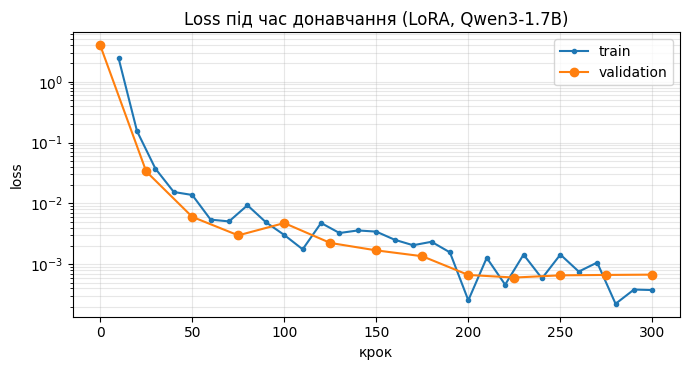

Мінімум validation loss: 0.0006 на кроці 225; останнє значення: 0.0007 на кроці 300
Validation loss не зростає після виходу на плато: ознак перенавчання немає, тож додаткових заходів не потрібно.


In [26]:
log = trainer.state.log_history
train_pts = {h["step"]: h["loss"] for h in log if "loss" in h}
val_pts = {h["step"]: h["eval_loss"] for h in log if "eval_loss" in h}
val_pts.setdefault(0, initial_eval["eval_loss"])
acc_pts = {h["step"]: h["eval_mean_token_accuracy"] for h in log if "eval_mean_token_accuracy" in h}

loss_df = pd.DataFrame({"train loss (середнє за 10 кроків)": pd.Series(train_pts), "validation loss": pd.Series(val_pts)})
if acc_pts:
    loss_df["val token accuracy"] = pd.Series(acc_pts)
loss_df = loss_df.sort_index().rename_axis("крок")
display(loss_df.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(train_pts), list(train_pts.values()), marker=".", label="train")
ax.plot(sorted(val_pts), [val_pts[s] for s in sorted(val_pts)], marker="o", label="validation")
ax.set(xlabel="крок", ylabel="loss", title="Loss під час донавчання (LoRA, Qwen3-1.7B)", yscale="log")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=120)
plt.show()

val_steps = sorted(val_pts)
BEST_VAL_STEP = min(val_steps[1:], key=val_pts.get)
final_val = val_pts[val_steps[-1]]
print(f"Мінімум validation loss: {val_pts[BEST_VAL_STEP]:.4f} на кроці {BEST_VAL_STEP}; останнє значення: {final_val:.4f} на кроці {val_steps[-1]}")
if final_val - val_pts[BEST_VAL_STEP] > 0.2 * val_pts[BEST_VAL_STEP] + 0.002:
    print("Validation loss зріс після мінімуму: ознака перенавчання, варто зменшити MAX_STEPS приблизно до кроку мінімуму.")
else:
    print("Validation loss не зростає після виходу на плато: ознак перенавчання немає, тож додаткових заходів не потрібно.")

## 1.5. Порівняння, аналіз помилок і загальні запити

Тепер донавчена модель (базова модель + адаптер, **з коротким промптом** `SYSTEM_FT`) відповідає на ті самі запити тих самих наборів, що й «до». Усе, що змінилося між етапами, — ваги й промпт.

In [27]:
ft_model = trainer.model
for set_name in ("val", "test_iid", "test_unseen", "natural"):
    run_eval(ft_model, "after", set_name, SYSTEM_FT)
save_results()
print({name: round(RES["after"][name]["summary"]["exact"], 3) for name in DATA})

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

{'val': 0.99, 'test_iid': 0.99, 'test_unseen': 0.985, 'natural': 0.957}


набір,val,test_iid,test_unseen,natural
n,200,400,200,70
до: exact,0.61,0.637,0.49,0.571
до: 95% ДІ,[0.54; 0.67],[0.59; 0.68],[0.42; 0.56],[0.45; 0.68]
після: exact,0.99,0.99,0.985,0.957
після: 95% ДІ,[0.96; 1.00],[0.97; 1.00],[0.96; 0.99],[0.88; 0.99]
гірше (b),1,1,1,0
краще (c),77,142,100,27
p (McNemar),5.2e-22,2.6e-41,8e-29,1.5e-08
до: чистий JSON,1.0,1.0,1.0,1.0
після: чистий JSON,1.0,1.0,1.0,1.0


Точність по полях:


test_iid        test_unseen        natural       
             before  after      before  after  before  after
category      0.935  0.998       0.935  1.000   0.943  0.986
brand         0.930  0.995       0.910  0.985   0.957  1.000
price_min     0.840  1.000       0.695  1.000   0.800  0.957
price_max     0.865  1.000       0.730  1.000   0.814  1.000
color         0.950  0.998       0.925  1.000   0.986  1.000
storage_gb    0.990  1.000       0.980  1.000   0.986  1.000
screen_in     0.995  1.000       0.995  1.000   0.971  0.986
wireless      0.952  1.000       0.980  1.000   0.900  1.000

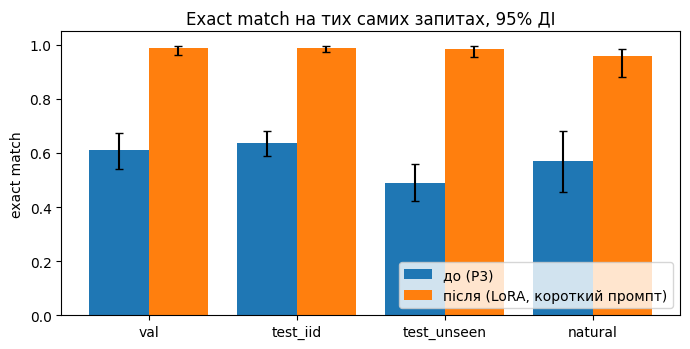

In [28]:
rows = []
for set_name in ("val", "test_iid", "test_unseen", "natural"):
    before, after = RES["before"][set_name], RES["after"][set_name]
    worse, better, p = mcnemar_exact([s["exact"] for s in before["scores"]], [s["exact"] for s in after["scores"]])
    (lo_b, hi_b), (lo_a, hi_a) = before["summary"]["exact_ci"], after["summary"]["exact_ci"]
    rows.append({"набір": set_name, "n": after["summary"]["n"],
                 "до: exact": round(before["summary"]["exact"], 3), "до: 95% ДІ": f"[{lo_b:.2f}; {hi_b:.2f}]",
                 "після: exact": round(after["summary"]["exact"], 3), "після: 95% ДІ": f"[{lo_a:.2f}; {hi_a:.2f}]",
                 "гірше (b)": worse, "краще (c)": better, "p (McNemar)": f"{p:.2g}",
                 "до: чистий JSON": round(before["summary"]["clean"], 3), "після: чистий JSON": round(after["summary"]["clean"], 3),
                 "до: строга схема": round(before["summary"]["strict"], 3), "після: строга схема": round(after["summary"]["strict"], 3)})
compare_table = pd.DataFrame(rows).set_index("набір")
display(compare_table.T)

field_rows = {}
for set_name in ("test_iid", "test_unseen", "natural"):
    for stage in ("before", "after"):
        field_rows[(set_name, stage)] = {k: RES[stage][set_name]["summary"][f"f_{k}"] for k in SCHEMA_KEYS}
print("Точність по полях:")
display(pd.DataFrame(field_rows).round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
sets = ["val", "test_iid", "test_unseen", "natural"]
for offset, stage, label in ((-0.2, "before", f"до ({BEST_PROMPT.split(':')[0]})"), (0.2, "after", "після (LoRA, короткий промпт)")):
    values = [RES[stage][s]["summary"]["exact"] for s in sets]
    errors = [[v - RES[stage][s]["summary"]["exact_ci"][0] for v, s in zip(values, sets)], [RES[stage][s]["summary"]["exact_ci"][1] - v for v, s in zip(values, sets)]]
    ax.bar([i + offset for i in range(4)], values, width=0.4, yerr=errors, capsize=3, label=label)
ax.set_xticks(range(4), sets)
ax.set(ylabel="exact match", ylim=(0, 1.05), title="Exact match на тих самих запитах, 95% ДІ")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("before_after.png", dpi=120)
plt.show()

In [29]:
print("Ті самі 8 запитів natural, відповіді після донавчання:")
show_answers("after", "natural", range(8))

Ті самі 8 запитів natural, відповіді після донавчання:
- 'айфон 13 128гб синій до 25 тис'
    відповідь: '{"category":"smartphone","brand":"Apple","price_min":null,"price_max":25000,"color":"blue","storage_gb":128,"screen_in":null,"wireless":null}'
    усі поля збігаються
- 'телефон самсунг до 10000 грн'
    відповідь: '{"category":"smartphone","brand":"Samsung","price_min":null,"price_max":10000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}'
    усі поля збігаються
- 'навушники бездротові jbl'
    відповідь: '{"category":"headphones","brand":"JBL","price_min":null,"price_max":null,"color":null,"storage_gb":null,"screen_in":null,"wireless":true}'
    усі поля збігаються
- 'ноутбук для ігор до 40 тис'
    відповідь: '{"category":"laptop","brand":null,"price_min":null,"price_max":40000,"color":null,"storage_gb":null,"screen_in":null,"wireless":null}'
    усі поля збігаються
- 'монітор 27 дюймів 144 гц'
    відповідь: '{"category":"monitor","brand":null,"price_min":null

### Ціна інференсу: промпт, затримка, памʼять

Донавчання переносить інструкцію з промпта у ваги, тож промпт стає значно коротшим. Чи стає від цього швидше, ми міряємо, а не припускаємо.

- **Затримка на один запит** (без батчування, так працює пошук у реальному часі): середній час відповіді на 20 запитів `test_iid` після прогріву, один запуск.
- **Час на 100 запитів** береться з часу оцінки `test_iid`. Для базової моделі з промптом P3 функція `generate` обмежує батч до 8 (довгий промпт, запас памʼяті GPU), а для донавченої використовується батч 16. Тож рядок «батч 16» у таблиці нижче для колонки «до» насправді відповідає батчу 8, і різниця частково пояснюється розміром батча, а не лише довжиною промпта.
- Адаптер **не злитий** із вагами: `merge_and_unload` міг би прибрати додаткові матричні множення LoRA, але цього ми не міряли.

In [30]:
def latency(model, system_prompt, shots=(), n=20):
    """Середній час відповіді на один запит без батчування (з прогрівом)."""
    queries = [r["text"] for r in DATA["test_iid"][:n]]
    generate(model, queries[:2], system_prompt, shots, batch_size=1, progress=False)
    torch.cuda.synchronize()
    start = time.time()
    generate(model, queries, system_prompt, shots, batch_size=1, progress=False)
    torch.cuda.synchronize()
    return (time.time() - start) / n


with ft_model.disable_adapter():
    base_latency = latency(ft_model, BEST_SYSTEM, BEST_SHOTS)
ft_latency = latency(ft_model, SYSTEM_FT)
COST = pd.DataFrame({
    f"до ({BEST_PROMPT.split(':')[0]})": {"токенів у промпті": prompt_tokens(BEST_SYSTEM, BEST_SHOTS), "затримка, с/запит (батч 1)": round(base_latency, 2),
                                          "батч 16, с на 100 запитів": round(100 * RES["before"]["test_iid"]["sec"] / len(DATA["test_iid"]), 1)},
    "після (LoRA)": {"токенів у промпті": prompt_tokens(SYSTEM_FT), "затримка, с/запит (батч 1)": round(ft_latency, 2),
                     "батч 16, с на 100 запитів": round(100 * RES["after"]["test_iid"]["sec"] / len(DATA["test_iid"]), 1)},
})
display(COST)
print(f"Вартість донавчання: {TRAIN_SEC / 60:.1f} хв на T4, адаптер {ADAPTER_MB:.0f} MB, пікова памʼять {PEAK_GB:.1f} GB")

,до (P3),після (LoRA)
токенів у промпті,1175.00,30.00
"затримка, с/запит (батч 1)",2.75,3.79
"батч 16, с на 100 запитів",66.30,29.90


Вартість донавчання: 9.7 хв на T4, адаптер 70 MB, пікова памʼять 4.1 GB


### Аналіз помилок

Дивимося на помилки донавченої моделі: **які поля** помиляються, **у яких групах запитів** помилок найбільше (за прихованою від моделі метою `meta` синтетичних наборів) і **як виглядають конкретні помилки**.

In [31]:
def error_types(stage, sets):
    """Скільки запитів мають помилку в кожній комбінації полів."""
    counter = Counter()
    for set_name in sets:
        for score in RES[stage][set_name]["scores"]:
            if score["exact"]:
                continue
            wrong = [k for k in SCHEMA_KEYS if not score["fields"][k]]
            counter["невалідний JSON" if not score["valid"] else " + ".join(wrong)] += 1
    return counter


ERR_TYPES = error_types("after", ("test_iid", "test_unseen", "natural"))
total_n = sum(len(DATA[s]) for s in ("test_iid", "test_unseen", "natural"))
print(f"Помилок після донавчання: {sum(ERR_TYPES.values())} із {total_n} запитів на трьох тестових наборах")
display(pd.DataFrame(ERR_TYPES.most_common(10), columns=["які поля хибні", "запитів"]).set_index("які поля хибні"))


def error_by_attribute(stage, sets=("test_iid", "test_unseen")):
    """Частка помилкових відповідей за значеннями прихованих ознак запиту (лише для синтетичних наборів)."""
    records = []
    for set_name in sets:
        for row, score in zip(DATA[set_name], RES[stage][set_name]["scores"]):
            m = row["meta"]
            records.append({"exact": score["exact"], "мова": m["lang"], "лінійка (iPhone…)": m["alias"], "друкарська помилка": m["typo"],
                            "RAM-пастка": m["ram_distractor"], "бренд кирилицею": m["brand_cyr"], "ціна": m["price"], "запис ціни": m["price_style"] or "—"})
    df = pd.DataFrame(records)
    parts = []
    for column in ("мова", "лінійка (iPhone…)", "друкарська помилка", "RAM-пастка", "бренд кирилицею", "ціна", "запис ціни"):
        grouped = df.groupby(column)["exact"].agg(n="count", помилок=lambda s: int((~s).sum()))
        grouped["помилок, %"] = (100 * grouped["помилок"] / grouped["n"]).round(1)
        grouped.index = [f"{column} = {value}" for value in grouped.index]
        parts.append(grouped)
    return pd.concat(parts)


ERR_BY_ATTR = error_by_attribute("after")
print("Частка помилок за групами запитів (test_iid + test_unseen), групи з n ≥ 15:")
display(ERR_BY_ATTR[ERR_BY_ATTR["n"] >= 15])

Помилок після донавчання: 10 із 670 запитів на трьох тестових наборах


,запитів
які поля хибні,
brand,5
color,1
category,1
price_min + screen_in,1
price_min,1
category + price_min,1


Частка помилок за групами запитів (test_iid + test_unseen), групи з n ≥ 15:


,n,помилок,"помилок, %"
мова = en,51,1,2.0
мова = ru,69,0,0.0
мова = ua,480,6,1.2
лінійка (iPhone…) = False,531,6,1.1
лінійка (iPhone…) = True,69,1,1.4
друкарська помилка = False,552,2,0.4
друкарська помилка = True,48,5,10.4
RAM-пастка = False,583,7,1.2
RAM-пастка = True,17,0,0.0
бренд кирилицею = False,532,6,1.1


In [32]:
def list_errors(stage, set_name, limit=12):
    """Друкує запити, у яких модель помилилась: запит, відповідь і які поля відрізняються від еталона."""
    shown = 0
    for i, (row, score) in enumerate(zip(DATA[set_name], RES[stage][set_name]["scores"])):
        if not score["exact"]:
            answer = RES[stage][set_name]["answers"][i]
            print(f"- {row['text']!r}\n    {short_diff(row['label'], answer)}")
            shown += 1
            if shown >= limit:
                break
    if shown == 0:
        print("  помилок немає")


for set_name in ("natural", "test_unseen", "test_iid"):
    n_err = sum(not s["exact"] for s in RES["after"][set_name]["scores"])
    print(f"\n=== {set_name}: {n_err} помилок із {len(DATA[set_name])} (показано до 12) ===")
    list_errors("after", set_name)

print("\nЗапити, де донавчена модель гірша за базову з найкращим промптом (на всіх тестових наборах):")
regressions = 0
for set_name in ("test_iid", "test_unseen", "natural"):
    for i, (b, a) in enumerate(zip(RES["before"][set_name]["scores"], RES["after"][set_name]["scores"])):
        if b["exact"] and not a["exact"]:
            regressions += 1
            if regressions <= 8:
                row = DATA[set_name][i]
                print(f"- [{set_name}] {row['text']!r}: {short_diff(row['label'], RES['after'][set_name]['answers'][i])}")
print(f"Усього таких запитів: {regressions}")


=== natural: 3 помилок із 70 (показано до 12) ===
- 'телевізор 43 до 12 тис'
    price_min: 4000 ≠ None; screen_in: None ≠ 43
- 'годинник samsung galaxy watch 6 до 10 тисяч'
    price_min: 6000 ≠ None
- 'powerbank anker 20000'
    category: 'powerbank' ≠ 'other'; price_min: 20000 ≠ None

=== test_unseen: 3 помилок із 200 (показано до 12) ===
- 'де купити білий планшшет менше ніж 5000 512 ГБ'
    brand: 'Google' ≠ None
- 'підкажіть vivobook асус у межах 25000 15,6"'
    brand: 'Acer' ≠ 'Asus'
- 'потрібні 2000 – 5000 hp принтери'
    brand: None ≠ 'HP'

=== test_iid: 4 помилок із 400 (показано до 12) ===
- 'де купити xiaomi гарінтуру дешевше восьми тисяч'
    color: 'gray' ≠ None
- 'looking for monnitor over 20000uah review'
    brand: 'Monitor' ≠ None
- 'купити моннітори 32 дюйм ціна від 8 000₴ до 15000₴ чорні'
    brand: 'Acer' ≠ None
- 'Шукаю 2000 - 10000 ганрітуру xiaomi з доставкою'
    category: 'smartphone' ≠ 'headphones'

Запити, де донавчена модель гірша за базову з найкращим п

### Перевірка загальних запитів поза задачею

Донавчання може «зіпсувати» універсальність моделі: вона починає відповідати JSON-фільтром на будь-яке питання (так званий витік формату) або гірше розв'язує звичайні завдання. Перевіряємо 8 запитів поза задачею **без системного промпта** на трьох варіантах однієї й тієї самої моделі: базова, донавчена (адаптер увімкнено) й базова ще раз (адаптер вимкнено через `disable_adapter()`: це контроль, що відмінності справді від адаптера). Відповіді перевіряються простими правилами (число, слово, наявність `def`), тож це швидка діагностика, а не повноцінний бенчмарк: 8 запитів дозволяють побачити *явну* деградацію, але не виміряти малу.

In [33]:
GENERAL = [
    ("Скільки буде 17 × 23? Відповідай лише числом.", lambda t: "391" in t),
    ("Яка столиця Франції? Відповідай одним словом.", lambda t: bool(re.search(r"(?i)париж|paris", t))),
    ("Переклади англійською: «Добрий день, як справи?»", lambda t: "how are you" in t.lower()),
    ("Напиши Python-функцію is_palindrome(s), яка повертає True, якщо рядок читається однаково в обидва боки.", lambda t: "def is_palindrome" in t),
    ("Назви три планети Сонячної системи.", lambda t: sum(p in t.lower() for p in ("меркур", "венер", "земл", "марс", "юпітер", "сатурн", "уран", "нептун")) >= 3),
    ("Скільки днів у лютому 2024 року? Відповідай числом.", lambda t: "29" in t),
    ("Поясни одним реченням, що таке оперативна памʼять (RAM).", lambda t: bool(re.search(r"(?i)пам.{1,2}ть|memory", t)) and not t.strip().startswith("{")),
    ("Напиши двома реченнями привітання з днем народження.", lambda t: len(t) > 30 and "{" not in t),
]


def looks_like_filter(text):
    """Чи відповідь на запит поза задачею є JSON-фільтром (витік формату)."""
    obj, _ = extract_json(text)
    return text.strip().startswith("{") or (obj is not None and "category" in obj)


def chat(model, prompt, max_new_tokens=160):
    """Відповідь на довільне питання без системного промпта (жадібна генерація, thinking вимкнено)."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


ft_model.eval()
GENERAL_ANSWERS = {"базова (адаптер вимкнено)": [], "донавчена (адаптер увімкнено)": []}
with ft_model.disable_adapter():
    GENERAL_ANSWERS["базова (адаптер вимкнено)"] = [chat(ft_model, prompt) for prompt, _ in GENERAL]
GENERAL_ANSWERS["донавчена (адаптер увімкнено)"] = [chat(ft_model, prompt) for prompt, _ in GENERAL]

summary_general = {}
for name, answers in GENERAL_ANSWERS.items():
    summary_general[name] = {"правильних відповідей": sum(check(a) for a, (_, check) in zip(answers, GENERAL)),
                             "відповідь = JSON-фільтр": sum(looks_like_filter(a) for a in answers)}
GENERAL_TABLE = pd.DataFrame(summary_general).T
display(GENERAL_TABLE.assign(із=len(GENERAL)))
for i, (prompt, check) in enumerate(GENERAL):
    print(f"\n▸ {prompt}")
    for name, answers in GENERAL_ANSWERS.items():
        mark = "✓" if check(answers[i]) else "✗"
        print(f"   {mark} {name}: {answers[i][:130]!r}")

,правильних відповідей,відповідь = JSON-фільтр,із
базова (адаптер вимкнено),6,0,8
донавчена (адаптер увімкнено),5,0,8



▸ Скільки буде 17 × 23? Відповідай лише числом.
   ✓ базова (адаптер вимкнено): '17 × 23 = 391'
   ✓ донавчена (адаптер увімкнено): '391'

▸ Яка столиця Франції? Відповідай одним словом.
   ✓ базова (адаптер вимкнено): 'Париж'
   ✓ донавчена (адаптер увімкнено): 'Париж'

▸ Переклади англійською: «Добрий день, як справи?»
   ✗ базова (адаптер вимкнено): 'Доброго дня, як справи?'
   ✗ донавчена (адаптер увімкнено): 'Доброго дня, как дела?'

▸ Напиши Python-функцію is_palindrome(s), яка повертає True, якщо рядок читається однаково в обидва боки.
   ✓ базова (адаптер вимкнено): 'Ви можете написати Python-функцію `is_palindrome(s)` так:\n\n```python\ndef is_palindrome(s):\n    # Видаляємо пробіли та розміщуємо р'
   ✓ донавчена (адаптер увімкнено): 'def is_palindrome(s):\n    return s == s[::-1]'

▸ Назви три планети Сонячної системи.
   ✓ базова (адаптер вимкнено): 'Три планети Сонячної системи — це:\n\n1. **Меркурій**  \n2. **Венера**  \n3. **Земля**  \n\nЦе планети, які відомі з точки з

### Публікація адаптера на Hugging Face Hub (необовʼязково, +1 бонусний бал)

Публікуємо **лише адаптер** (≈ десятки MB), не злиту модель і не ваги базової моделі. Для цього: створіть на huggingface.co токен із правами **write** (Settings → Access Tokens), поставте `PUSH_TO_HUB = True`, замініть `HUB_REPO_ID` на `ваш_логін/назва` і запустіть клітинку; Colab попросить токен. У репозиторій лабораторної (GitHub) ваги не додаються: у звіті достатньо посилання на Hub.

In [34]:
PUSH_TO_HUB = False
HUB_REPO_ID = "ВАШ_ЛОГІН/qwen3-1.7b-product-query-lora"

if PUSH_TO_HUB:
    from huggingface_hub import HfApi, notebook_login

    notebook_login()
    ft_model.push_to_hub(HUB_REPO_ID)          # лише адаптер і adapter_config.json
    best_after = RES["after"]["natural"]["summary"]["exact"]
    card = f"""---
base_model: {MODEL_NAME}
library_name: peft
license: apache-2.0
language: [uk, ru, en]
---
# Адаптер LoRA для Qwen3-1.7B: пошуковий запит товару → JSON-фільтр

Навчальний проєкт (лабораторна робота 5, донавчання моделей). Адаптер перетворює україномовний (а також російський чи англійський) запит інтернет-магазину електроніки на JSON із полями
`category, brand, price_min, price_max, color, storage_gb, screen_in, wireless`.

- Базова модель: [{MODEL_NAME}](https://huggingface.co/{MODEL_NAME}) (Apache 2.0).
- Дані: синтетичні запити з власного генератора (4000 для тренування) і 70 запитів, розмічених вручну (для оцінки).
- Метод: SFT з LoRA (r=16, alpha=32), {MAX_STEPS} кроків, fp16, T4.
- Exact match на 70 запитах, розмічених вручну: {best_after:.2f}.

Системний промпт: `{SYSTEM_FT}`.
"""
    HfApi().upload_file(path_or_fileobj=card.encode("utf-8"), path_in_repo="README.md", repo_id=HUB_REPO_ID)
    print(f"Адаптер опубліковано: https://huggingface.co/{HUB_REPO_ID}")
else:
    print("Публікацію вимкнено (PUSH_TO_HUB = False)")

Публікацію вимкнено (PUSH_TO_HUB = False)


## 1.6. Звіт

Це статичний текст: усі числа взято з виводів клітинок вище (один запуск на T4 з фіксованим seed). Якщо ноутбук запустити знову, значення можуть трохи відрізнятися, і текст доведеться звірити з виводами.

### Задача і чому потрібне донавчання

Задача: перетворити пошуковий запит користувача інтернет-магазину електроніки (українською, інколи російською чи англійською) на JSON-фільтр із 8 полями (`category`, `brand`, `price_min`, `price_max`, `color`, `storage_gb`, `screen_in`, `wireless`), який без обробки передається в код пошуку по каталогу. Помилка в будь-якому полі дає покупцю хибну видачу, тому головна метрика — збіг усіх 8 полів.

Без донавчання базова модель справляється тільки з довгим промптом. З одним реченням (P1, 76 токенів) exact match на `val` дорівнює 0%, зі специфікацією (P2, 599 токенів) — 29,5%, зі специфікацією й 8 прикладами (P3, 1175 токенів) — 61,0%. Проблема не у синтаксисі: JSON валідний у 100% відповідей P2 і P3. Проблема в конвенціях схеми: наприклад, точність `price_max` на `test_unseen` лише 73%, а серед перших 8 запитів `natural` тричі «до N» потрапило в `price_min`. Донавчання переносить ці конвенції у ваги й скорочує промпт до 30 токенів. RAG тут не потрібен: моделі бракує не знань із документів, а навички відображення тексту в схему.

### Модель і дані

Модель `Qwen/Qwen3-1.7B` (Apache 2.0), режим міркувань вимкнено. Моделі 0,6B і 4B для цієї задачі не пробували.

Дані походять із двох джерел, створених у межах роботи:

| набір | розмір | призначення |
|---|---|---|
| `train` | 4000 | тренування |
| `val` | 200 | validation loss і вибір промпта для «до» |
| `test_iid` | 400 | тест тієї самої природи, що й `train` |
| `test_unseen` | 200 | формулювання цін, яких немає в `train` |
| `natural` | 70 | запити, складені й розмічені вручну, поза генератором |

Синтетичний генератор має 13 категорій, 49 брендів (36 із кириличними написаннями), 3 мови (80% укр., 12% рос., 8% англ.), 6 стилів запису цін, відмінювання, друкарські помилки та «пастки» (RAM поруч із памʼяттю накопичувача, товари поза переліком). Мітка будується з тих самих значень, що й текст запиту, тому помилок розмітника немає. Витік між наборами виключено програмною перевіркою. Набір `natural` — це 70 запитів, складених для цієї роботи за зразком типових запитів, а не вибірка з логів реального магазину.

### Метрика й результат до донавчання

Основна метрика — exact match (усі 8 полів збігаються з еталоном). Додатково: валідний JSON (вдалося розібрати), чистий JSON (розбирається `json.loads` без обробки), строга схема (рівно 8 ключів, дозволені значення й типи), точність по полях, 95% інтервал Вілсона. «До» і «після» порівнюються на тих самих запитах точним тестом знаків (McNemar). Наївний базис (найчастіше значення кожного поля в `train`) дає 0–1,5%.

Промпт для «до» обрано за exact match на `val` (не на тесті): P3. Це найкращий із трьох промптів, які ми написали, а не верхня межа того, що дає промптинг.

| набір | n | exact match | 95% ДІ | чистий JSON | строга схема |
|---|---|---|---|---|---|
| `val` | 200 | 61,0% | [54%; 67%] | 100% | 91,5% |
| `test_iid` | 400 | 63,7% | [59%; 68%] | 100% | 88,7% |
| `test_unseen` | 200 | 49,0% | [42%; 56%] | 100% | 94,0% |
| `natural` | 70 | 57,1% | [45%; 68%] | 100% | 91,4% |

Найслабші поля до донавчання: `price_min` і `price_max` (на `test_unseen` 69,5% і 73,0%, на `natural` 80,0% і 81,4%).

### Метод донавчання й гіперпараметри

SFT з LoRA (`trl.SFTTrainer` + `peft`), без квантизації: `r` = 16, `lora_alpha` = 32, `lora_dropout` = 0,05, `target_modules` = `all-linear`; `learning_rate` 2e-4 з косинусним спадом і 10 кроками розігріву; ефективний батч 8 × 2 = 16; 300 кроків (≈ 1,2 епохи); `max_length` 256; `fp16`, `gradient_checkpointing`; loss лише на відповіді асистента (`assistant_only_loss`). Тренується 17,4 млн із 1,74 млрд параметрів (1,00%).

Тренування тривало 9,7 хв на T4, пікова памʼять GPU 4,1 GB, адаптер займає 70 MB. Validation loss: 3,973 до тренування, 0,0335 на кроці 25, мінімум 0,0006 на кроці 225, наприкінці 0,0007 (token accuracy 99,98%). Зростання validation loss немає, тож ознак перенавчання на `val` не видно. Адаптер збережено після останнього кроку (чекпоінт за `val` не вибирався). Це один запуск з одним набором гіперпараметрів: підбору й повторів з іншими seed не було.

### Результат після донавчання

| набір | до | після | 95% ДІ після | гірше / краще | p (McNemar) |
|---|---|---|---|---|---|
| `val` | 61,0% | 99,0% | [96%; 100%] | 1 / 77 | 5,2·10⁻²² |
| `test_iid` | 63,7% | 99,0% | [97%; 100%] | 1 / 142 | 2,6·10⁻⁴¹ |
| `test_unseen` | 49,0% | 98,5% | [96%; 99%] | 1 / 100 | 8·10⁻²⁹ |
| `natural` | 57,1% | 95,7% | [88%; 99%] | 0 / 27 | 1,5·10⁻⁸ |

Чистий JSON після донавчання — 100% на всіх наборах; строга схема — 100% на синтетичних наборах і 98,6% на `natural`. На `natural` точність `price_min` зросла з 80,0% до 95,7%, `price_max` — з 81,4% до 100%, `wireless` — з 90,0% до 100%.

**Ціна інференсу** (див. пояснення до таблиці в розділі 1.5):

| | до (P3) | після (LoRA) |
|---|---|---|
| токенів у промпті | 1175 | 30 |
| затримка на запит, батч 1, с | 2,75 | 3,79 |
| с на 100 запитів (до: батч 8; після: батч 16) | 66,3 | 29,9 |

Промпт скоротився на 97%. Затримка одного запиту **не зменшилась, а зросла на 38%**: ймовірна причина — додаткові множення LoRA в незлитому адаптері (ми це не перевіряли). Скорочення часу на 100 запитів у 2,2 раза зроблено з батчем 16 проти 8, тож його не можна приписувати лише довжині промпта.

**Загальні запити поза задачею** (8 питань без системного промпта, прості правила перевірки, тому це швидка діагностика, а не бенчмарк):

| | правильних | відповідь = JSON-фільтр |
|---|---|---|
| базова (адаптер вимкнено) | 6 з 8 | 0 |
| донавчена | 5 з 8 | 0 |

Витоку формату немає: на жодне з 8 питань донавчена модель не відповіла JSON-фільтром. Різниця в одну відповідь: привітання «Доброго дня! 🎉» не відповідає завданню (два речення з днем народження). Обидві моделі не переклали фразу англійською й помилилися в днях лютого 2024 (відповіли 28). У перекладі донавчена відповідь містить російське «как дела»; одного випадку замало, щоб казати про зсув у бік російської. У кількох відповідях донавчена модель коротша за базову («391» замість «17 × 23 = 391», функція без пояснень). Розбіжність між моделями лише в одному питанні з 8 (точний тест знаків дає p = 1), тож при n = 8 можна помітити лише явну деградацію, а малу виміряти неможливо.

### Аналіз помилок

Після донавчання 10 помилок на 670 запитах трьох тестових наборів (1,5%): `test_iid` — 4, `test_unseen` — 3, `natural` — 3. Хибні поля: `brand` (5), `category` (1), `color` (1), `price_min` (2), комбінації (`price_min` + `screen_in`, `category` + `price_min`) — по 1.

- **Друкарські помилки** — найбільша група ризику: 5 помилок із 48 запитів з опечаткою (10,4%) проти 2 із 552 без опечаток (0,4%); це 5 із 7 помилок на синтетичних наборах («планшшет», «гарінтуру», «ганрітуру», «monnitor», «моннітори»). П'ять помилок `brand`: у трьох модель вигадала бренд там, де його немає (Google, «Monitor», Acer), в одній переплутала Asus з Acer («vivobook асус»), в одній пропустила HP («2000 – 5000 hp принтери»).
- **Набір `natural`: усі три помилки стосуються чисел, які не є ціною або стоять без пояснення.** «galaxy watch 6 до 10 тисяч» → `price_min` 6000 (імовірно, «6 до 10 тисяч» прочитано як діапазон цін). «телевізор 43 до 12 тис» → хибний `price_min` 4000 і пропущена діагональ 43 (у `train` усі діагоналі без «дюймів» мають слово «діагональ»). «powerbank anker 20000» → недозволена категорія `powerbank` (єдине порушення строгої схеми) і `price_min` 20000, хоча за еталоном це не ціна. У генераторі немає чисел із «гц», «кг» чи «mAh», а в промптах P2 і P3 для базової моделі є правило ігнорувати такі числа: базова модель мала цю підказку, донавчена в даних її не бачила. Це гіпотеза з трьох прикладів, а не доведена причина.
- **Донавчена модель гірша за базову** лише на двох запитах із 670: «моннітори …» (бренд Acer замість `null`) і «vivobook асус …» (Acer замість Asus).
- В інших зрізах (мова, лінійка продукту, RAM-пастка, кирилічний бренд, запис ціни) помилок від 0 до 7 на групу: порівнювати групи за такими числами не можна.

Що можна зробити далі (не перевірялось): додати в генератор числа з «гц», «кг», «mAh», діагоналі без пояснення, «N до M» поруч із номером моделі й більше опечаток у назвах товарів і брендів; обмежити декодування схемою (перелік категорій), щоб категорія `powerbank` була неможливою; злити адаптер (`merge_and_unload`) і перевимірити затримку.

### Висновок

Донавчання з LoRA на 4000 синтетичних прикладах підняло exact match з 57,1% до 95,7% на 70 запитах `natural` (з 40 до 67 правильних відповідей; жодна відповідь не стала гіршою; p = 1,5·10⁻⁸) і з 49,0% до 98,5% на формулюваннях цін, яких немає в `train`. Промпт скоротився з 1175 до 30 токенів, а формат став повністю передбачуваним (чистий JSON 100%, строга схема 98,6–100%). Ціна: 9,7 хв тренування на безкоштовному T4, адаптер 70 MB, одна відповідь із 8 у перевірці загальних запитів, затримка одного запиту на 38% більша за базову (адаптер не злито).

Гіпотези розділу 1.1 перевірено так. Конвенції схеми (ціни, бренди, памʼять проти RAM) справді перейшли у ваги, а промпт скоротився з 1175 до 30 токенів. Припущення, що мала модель погано тримає формат, підтвердилось лише частково: з промптом P3 базова модель уже давала валідний JSON у 100% відповідей, строга схема була в 89–94%, а виграш іде здебільшого з боку семантики, передусім цін. Очікуване прискорення відповіді не підтвердилось: затримка на один запит зросла з 2,75 до 3,79 с.

**Обмеження.**

- Синтетичні тести `val`, `test_iid` і `test_unseen` створені тим самим генератором, що й `train`, тому 98,5–99% на них відображають вивчення граматики генератора. Реалістичнішою є перевірка на `natural`, але це лише 70 запитів, складених для роботи (95% ДІ [88%; 99%]), а не логи реального магазину; результат на справжніх запитах може бути нижчим.
- «До» — це найкращий із трьох наших промптів. Сильніший промпт або більша модель (наприклад, Qwen3-4B із тим самим промптом) могли б дати вищий базовий результат; цього ми не перевіряли.
- Порівняння часу на 100 запитів зроблено з різними батчами (8 проти 16), затримка виміряна один раз на 20 запитах.
- Один запуск тренування й одна конфігурація: розкиду за seed і впливу гіперпараметрів ми не вимірювали.
- Перевірка загальних здібностей — 8 запитів з простими правилами, тож вона не виключає малої деградації.

Адаптер збережено локально (`ft_adapter`, 70 MB) і в репозиторій не додається; публікація на Hugging Face Hub — необовʼязкова клітинка вище (за замовчуванням вимкнена).


In [36]:
import pandas as pd


def timing_report(top=6):
    """Скільки часу забрали клітинки ноутбука (за даними службової клітинки з початку ноутбука)."""
    times = pd.DataFrame(CELL_TIMES)
    print(f"Виконано клітинок: {len(times)}; сумарний час їх виконання: {times['sec'].sum() / 60:.1f} хв")
    print(f"Найдовші {top} клітинок:")
    return times.sort_values("sec", ascending=False).head(top)[["cell", "sec", "code"]].reset_index(drop=True)


timing_report()

Виконано клітинок: 34; сумарний час їх виконання: 32.3 хв
Найдовші 6 клітинок:


,cell,sec,code
0,25,593.3,initial_eval = trainer.evaluate() # va...
1,21,443.6,# Найкращий промпт міряємо на тестових наборах...
2,20,298.0,"SHOTS = pick_fewshot(splits[""train""])"
3,27,267.7,ft_model = trainer.model
4,30,142.6,"def latency(model, system_prompt, shots=(), n=..."
5,18,51.1,# Модель завантажуємо у fp16 (Qwen3 збережено ...


In [37]:
FINAL = {
    "best_prompt": BEST_PROMPT,
    "prompt_val_exact": {k: round(v["summary"]["exact"], 3) for k, v in PROMPT_RES.items()},
    "exact_before": {s: round(RES["before"][s]["summary"]["exact"], 3) for s in DATA},
    "exact_after": {s: round(RES["after"][s]["summary"]["exact"], 3) for s in DATA},
    "train_min": round(TRAIN_SEC / 60, 1), "peak_gb": round(PEAK_GB, 1), "adapter_mb": round(ADAPTER_MB),
    "val_loss": {"step0": round(val_pts[0], 4), "min": round(val_pts[BEST_VAL_STEP], 4), "min_step": BEST_VAL_STEP, "final": round(final_val, 4)},
    "general": GENERAL_TABLE.to_dict(),
    "cost": COST.to_dict(),
}
print(json.dumps(FINAL, ensure_ascii=False, indent=1))

{
 "best_prompt": "P3: специфікація + 8 прикладів",
 "prompt_val_exact": {
  "P1: одне речення": 0.0,
  "P2: специфікація": 0.295,
  "P3: специфікація + 8 прикладів": 0.61
 },
 "exact_before": {
  "val": 0.61,
  "test_iid": 0.637,
  "test_unseen": 0.49,
  "natural": 0.571
 },
 "exact_after": {
  "val": 0.99,
  "test_iid": 0.99,
  "test_unseen": 0.985,
  "natural": 0.957
 },
 "train_min": 9.7,
 "peak_gb": 4.1,
 "adapter_mb": 70,
 "val_loss": {
  "step0": 3.9726,
  "min": 0.0006,
  "min_step": 225,
  "final": 0.0007
 },
 "general": {
  "правильних відповідей": {
   "базова (адаптер вимкнено)": 6,
   "донавчена (адаптер увімкнено)": 5
  },
  "відповідь = JSON-фільтр": {
   "базова (адаптер вимкнено)": 0,
   "донавчена (адаптер увімкнено)": 0
  }
 },
 "cost": {
  "до (P3)": {
   "токенів у промпті": 1175.0,
   "затримка, с/запит (батч 1)": 2.75,
   "батч 16, с на 100 запитів": 66.3
  },
  "після (LoRA)": {
   "токенів у промпті": 30.0,
   "затримка, с/запит (батч 1)": 3.79,
   "батч 16, с 